# Simulating Timed Transfers and Bus Holding at Borella for Kadawatha-Pettah Metro Passengers

*Provenance: AI-generated.*

Lanka Metro Transit operates fixed-schedule metro buses on Route CM01 (Makumbura-Colombo Fort/Pettah) and Route CM03 (Makumbura-Kadawatha), both stopping at Borella without a direct Kadawatha-Pettah service. This notebook develops a three-layer stochastic discrete-event simulation of all four bus approach legs to Borella (discrete-time Markov traffic congestion, stop-by-stop Poisson passenger boarding and alighting with 80-passenger bus capacity, and Borella interchange transfer queueing), verifies the simulator against eight independent analytical, limiting-case, conservation, and variance-reduction checks, and evaluates schedule-based holding, real-time ETA-based holding, and route-level timetable shifts using common random numbers and 95% confidence intervals.

In [1]:
!pip install -q numpy pandas scipy matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import heapq
import io
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm

SEED = 42
root_seed_sequence = np.random.SeedSequence(SEED)

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "axes.titlesize": 11.5,
    "axes.labelsize": 10,
})

FIGURES_DIR = Path("figures") if Path("notebook").exists() or Path("data").exists() else Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"SEED = {SEED}")
print(f"numpy {np.__version__}, scipy {scipy.__version__}, matplotlib {plt.matplotlib.__version__}, pandas {pd.__version__}")

SEED = 42
numpy 2.5.5, scipy 1.18.1, matplotlib 3.11.2, pandas 3.1.1


## 1. Problem and question

*Provenance: AI-generated.*

Two Lanka Metro Transit routes intersect at Borella in Colombo:

- **Route CM01:** Makumbura to Colombo Fort/Pettah via Sethsiripaya, Rajagiriya, **Borella (Singer Mega)**, and Town Hall (12 daily trips per direction).
- **Route CM03:** Makumbura to Kadawatha via Apeksha Hospital, Nawinna, Narahenpita Junction, **Borella 02 (YMBA)**, Cambell Park, and Kelaniya University (12 northbound trips, 11 southbound trips).

No single route connects Kadawatha directly with Pettah. Introducing a part-paid through-ticket with one transfer at Borella serves two simultaneous passenger streams. The passenger pays part of the fare on the first bus and the balance on the connecting bus, provided they board it within the ticket validity window (proposed: 2 hours). Seats are not reserved, so boarding at Borella is first come, first served: a passenger who cannot board waits for the next Metro bus or leaves to use other transport.

| Transfer group | Trip direction | Feeder bus leg | Connecting bus leg |
|---|---|---|---|
| Group A | Kadawatha to Pettah | `CM03_KAD_to_MAK` | `CM01_MAK_to_FOR` |
| Group B | Pettah to Kadawatha | `CM01_FOR_to_MAK` | `CM03_MAK_to_KAD` |

Because CM01 and CM03 operate on 60-to-90-minute off-peak headways without coordinated Borella transfer windows, traffic variability, stop dwell times, and full buses ($C = 80$) make connections unreliable, and missing a connection imposes roughly an hour of extra waiting.

**Research question:** What holding rule (no holding, schedule-based holding, or real-time ETA-based holding) and route-level timetable shift $\Delta$ at Borella minimize missed connections across both transfer directions simultaneously without imposing excessive delay on passengers already on board?

## 2. Model, assumptions and equations

*Provenance: AI-generated.*

### Concepts and Methods Applied

| Modelling concept | Role in this simulator | Equations and code routines |
|---|---|---|
| Discrete-event simulation and queueing | Primary: stop-level FIFO passenger queues and `heapq` Borella transfer event loop with tie-breaking | `simulate_leg_day`, `simulate_direction_transfers` |
| Input modelling and random variate generation | Primary: explicit inverse-transform exponential arrivals, uniform destinations, discrete Markov lookup, Knuth Poisson counts, Box-Muller normal ETA noise | `sample_exponential_interarrival`, `sample_discrete_state`, `sample_poisson_knuth`, `sample_standard_normal_box_muller` |
| Markov chains (DTMC) | Supporting: 3-state peak/off-peak traffic congestion chain calibrated via stationary distribution and bisection | `build_parametric_transition_matrix`, `compute_stationary_distribution`, `calibrate_jam_param_bisection` |
| Monte Carlo integration and law of large numbers | Supporting: multi-day replication ensembles with common random numbers (`SeedSequence`), 95% confidence intervals, and $O(R^{-1/2})$ convergence scaling | `precompute_day_inputs`, `summarize_ci`, convergence check X2 |

### Timetable Cleaning, Borella Interpolation, and Target Mapping

- **Timetable cleaning (`CM03-MAK-02`):** Trip `CM03-MAK-02` (05:45 from Makumbura) exhibits a $+60\text{ min}$ offset on intermediate columns (`Nawinna` 07:18 through `Kelaniya University` 08:47), while its origin (`05:45`) and destination (`08:05`) match the standard 140-minute runtime. Subtracting $60\text{ min}$ from those four intermediate columns restores strict monotonicity across all timepoints.
- **Borella interpolation:** Borella is not a published timepoint. Given bracketing scheduled timepoints $T_{\text{prev}}$ and $T_{\text{next}}$ and placeholder fraction $\lambda = 0.5$:

$$T_{\text{Borella,sched}} = T_{\text{prev}} + \lambda \left(T_{\text{next}} - T_{\text{prev}}\right)$$

- **Target connector mapping:** Each feeder trip $f$ is assigned to the earliest opposite-direction connector trip $c(f)$ whose scheduled Borella time satisfies $T_{c,\text{sched}} \ge T_{f,\text{sched}}$ (or labelled `out_of_window` if no later connector exists). With walking time $w = 3.5\text{ min}$, the scheduled transfer slack is:

$$s_f = T_{c(f),\text{sched}} - \left(T_{f,\text{sched}} + w\right)$$

  Positive slack ($s_f > 0$) gives a scheduled buffer, whereas tight near-zero or slightly negative slack (such as $s_f = -0.5\text{ min}$ on afternoon Group A pairs and morning Group B `CM01-FOR-03`) indicates connections that fail without holding or timetable adjustment.

### Layer 1: Discrete-Time Markov Traffic Model

Each corridor evolves on $\Delta t = 5\text{ min}$ slots over three congestion states $S_t \in \{0:\text{Free},\, 1:\text{Slow},\, 2:\text{Jammed}\}$ with state speeds $v = (36, 20, 10)\text{ km/h}$ when the `cmb_traffic` corridor file is available (the default) or $v = (30, 15, 5)\text{ km/h}$ in the synthetic fallback. The higher empirical values keep the observed off-peak target inside the reachable bracket $[\bar{v}(0.85), \bar{v}(0.01)]$. Peak windows are 06:00-09:00 and 17:00-20:00 (Amalan, 2021). Using jam-tendency parameter $p \in [0.01, 0.85]$:

$$P(p) = \begin{pmatrix} 1 - p & 0.7p & 0.3p \\ 0.4(1 - p) & 0.4 & 0.2 + 0.4p \\ 0.1(1 - p) & 0.3(1 - p) & 0.6 + 0.4p \end{pmatrix}$$

The stationary distribution $\pi^*(p)$ solves $\pi^*(p) P(p) = \pi^*(p)$ with $\sum_k \pi^*_k = 1$, giving stationary mean speed $\bar{v}(p) = \sum_{k=0}^2 \pi^*_k(p) v_k$. Bisection solves for $p_{\text{offpeak}}$ and $p_{\text{peak}}$ against the mean speed of the six `cmb_traffic` corridors ($29.37$ and $24.10\text{ km/h}$; synthetic fallback $22.0$ and $14.0\text{ km/h}$). Given state $i$ and $U \sim \text{Uniform}(0, 1)$, transitions use explicit inverse-transform cumulative lookup:

$$j = \min\left\{k \in \{0, 1, 2\} : \sum_{m=0}^{k} P_{i,m} \ge U\right\}$$

Per-leg bus speed scale factors $\alpha_{\ell}$ are calibrated by bisection so mean simulated origin-to-Borella runtime matches the published timetable runtime within $1\%$.

### Layer 2: Stop-by-Stop Bus Journey, Arrivals, and Dwell Time

At each stop $s$, passenger arrivals begin $30\text{ min}$ before the leg's first scheduled departure with rate $\lambda_s(t) = \lambda_{s,0} \cdot m(t)$, where $m(t) = 1.35$ during peak periods and $0.85$ off-peak. Inter-arrival times and downstream destinations are generated explicitly via inverse transform:

$$\Delta\tau = -\frac{\ln(1 - U)}{\lambda_s(t)}, \qquad d \sim \text{Uniform}\{s+1, \dots, n_{\text{stops}}-1\}$$

At stop $s$, $a_s$ on-board passengers alight, and $b_s = \min(q_s, C - (\text{load}_s - a_s))$ waiting passengers board in FIFO order up to bus capacity $C = 80$. Stop dwell time is linear:

$$t_{\text{dwell},s} = \frac{t_{\text{door}} + t_{\text{alight}}\, a_s + t_{\text{board}}\, b_s}{60}\quad [\text{min}]$$

with $t_{\text{door}} = 12\text{ s}$, $t_{\text{alight}} = 2\text{ s/pax}$, and $t_{\text{board}} = 3\text{ s/pax}$.

### Layer 3: Borella Transfer Queueing, Holding Policies, and Objective

Each feeder trip $f$ carries $m_f \sim \text{Poisson}(5)$ through-ticket passengers (Knuth algorithm) who become ready at $T_{f,\text{ready}} = T_{f,\text{arr,Borella}} + w$. Buses keep their published times only at the origin terminal, so a connector leaves Borella as soon as it has served the stop:

$$T_{c,\text{base}} = T_{c,\text{arr,Borella}} + t_{c,\text{dwell}}$$

Let $\mathcal{F}_c = \{f : c(f) = c\}$ be the protected feeders targeting connector $c$, and let $T_{c,\text{cap}} = T_{c,\text{base}} + h$ be the latest departure allowed by holding:

1. **No holding (`none`):** Connector $c$ departs at $T_{c,\text{dep}} = T_{c,\text{base}}$.
2. **Schedule holding (`schedule`):** Connector $c$ waits for all protected feeders, up to the cap:

$$T_{c,\text{dep}} = \min\left(T_{c,\text{cap}},\; \max\left(T_{c,\text{base}},\; \max_{f \in \mathcal{F}_c} T_{f,\text{ready}}\right)\right)$$

3. **Real-time ETA holding (`realtime`):** Using estimated feeder ready time $\hat{T}_{f,\text{ready}} = T_{f,\text{ready}} + \varepsilon_f$ with $\varepsilon_f \sim \mathcal{N}(0, \sigma_{\text{eta}}^2)$ generated via Box-Muller transform, the connector protects only feeders predicted to be catchable, $\mathcal{F}_c^{\text{ETA}} = \{f \in \mathcal{F}_c : \hat{T}_{f,\text{ready}} \le T_{c,\text{cap}}\}$, and skips holding if $\mathcal{F}_c^{\text{ETA}}$ is empty or already ready.

**First-come, first-served boarding.** Local Borella passengers and through-ticket passengers form one queue ordered by arrival time and board up to $C - N_c$ free places, where $N_c$ is the connector load after Borella alighting. No seats are reserved.

**Patience and ticket validity.** A passenger who misses the planned connector (timing miss) or is refused by a full bus (capacity miss) waits for the next connector only if it is scheduled within the patience limit $P$ of the current time $t$ and within the ticket validity $V$ of their arrival at Borella:

$$\text{wait} \iff T_{\text{next,sched}} - t \le P \quad\text{and}\quad T_{\text{next,sched}} - T_{f,\text{ready}} \le V$$

Otherwise the passenger is **lost** to other transport and is charged the time already waited plus an alternative-travel penalty $\pi_{\text{alt}}$. The same patience rule applies to local passengers left behind by full buses at every stop. Feeder trips with no later connector in the day (`out_of_window`) send all their passengers to other transport at cost $\pi_{\text{alt}}$, so a timetable shift cannot lower the cost by pushing passengers out of the analysis window.

Policy performance is evaluated via expected daily equivalent passenger-minutes:

$$J(h, \Delta) = w_{\text{wait}}\, \mathbb{E}\left[\sum_{i} W_i + \pi_{\text{alt}} N_{\text{oow}}\right] + w_{\text{hold}}\, \mathbb{E}\left[\sum_{b} N_b \cdot \text{hold}_b\right], \qquad w_{\text{wait}} = 2.0,\; w_{\text{hold}} = 1.0$$

where $W_i$ is the Borella wait of in-window passenger $i$ (including $\pi_{\text{alt}}$ when lost) and $N_{\text{oow}}$ is the number of out-of-window passengers.

### Parameter Summary and Data Provenance

| Parameter | Baseline value | Unit | Provenance / status |
|---|---|---|---|
| Schedules (CM01, CM03) | 47 daily trips | HH:MM | Empirical: LMT-GO app (10 Nov 2026), cross-checked on metrobus.lk |
| Bus capacity $C$ | 80 | pax | Empirical: LMT-GO bus specification |
| Peak windows | 06:00-09:00, 17:00-20:00 | HH:MM | Literature: Amalan (2021) |
| Dwell parameters ($t_{\text{door}}, t_{\text{alight}}, t_{\text{board}}$) | 12, 2, 3 | s, s/pax | Literature-anchored typical urban bus dwell values |
| Segment distances | Leg arrays | km | Placeholder until stop-to-stop Google Maps table is entered |
| Borella fraction $\lambda$, walk time $w$ | 0.50, 3.5 | -, min | Placeholder until Borella stop survey is measured |
| Off-peak / peak target speeds | 29.37 / 24.10 | km/h | Empirical: mean of six `cmb_traffic` corridors (synthetic fallback 22.0 / 14.0 when the file is absent) |
| Base stop arrival rates $\lambda_{s,0}$ | 0.10-0.45 | pax/min | Synthetic/calibrated to Amalan (2021) 55-95% off-peak and 93-140% peak loads |
| Transfer demand mean $m$ | 5.0 | pax/feeder | Synthetic assumption (tested across 3-8 in sensitivity analysis) |
| Passenger patience $P$ | 60 (30-120 swept) | min | Assumption: about one off-peak headway; the part-paid ticket encourages waiting |
| Ticket validity $V$ | 120 | min | Proposed fare-integration rule (part-paid ticket valid for 2 hours) |
| Alternative-travel penalty $\pi_{\text{alt}}$ | 60 | min | Assumption |
| Connector waits for Borella schedule | No | - | Assumption: buses keep published times only at the origin terminal |

## 3. Implementation

*Provenance: AI-generated.*

In [3]:
WALK_TIME_PLACEHOLDER_MIN = 3.5
BORELLA_INTERPOLATION_PLACEHOLDER = 0.5

EMBEDDED_TIMETABLES = {
    "cm01_makumbura_to_fort.csv": (
        "trip_id,Makumbura,Sethsiripaya,Rajagiriya,Town Hall,Colombo Fort\n"
        "CM01-MAK-01,05:30,06:22,06:37,07:01,07:20\n"
        "CM01-MAK-02,06:15,07:07,07:22,07:46,08:05\n"
        "CM01-MAK-03,06:45,07:37,07:52,08:16,08:35\n"
        "CM01-MAK-04,07:15,08:07,08:22,08:46,09:05\n"
        "CM01-MAK-05,08:15,09:07,09:22,09:46,10:05\n"
        "CM01-MAK-06,09:45,10:37,10:52,11:16,11:35\n"
        "CM01-MAK-07,10:45,11:37,11:52,12:16,12:35\n"
        "CM01-MAK-08,12:15,13:07,13:22,13:46,14:05\n"
        "CM01-MAK-09,13:30,14:22,14:37,15:01,15:20\n"
        "CM01-MAK-10,14:30,15:22,15:37,16:01,16:20\n"
        "CM01-MAK-11,15:30,16:22,16:37,17:01,17:20\n"
        "CM01-MAK-12,16:30,17:22,17:37,18:01,18:20\n"
    ),
    "cm01_fort_to_makumbura.csv": (
        "trip_id,Colombo Fort,Pettah,Town Hall,Rajagiriya,Sethsiripaya,Makumbura\n"
        "CM01-FOR-01,07:30,07:32,07:49,08:13,08:28,09:20\n"
        "CM01-FOR-02,08:15,08:17,08:34,08:58,09:13,10:05\n"
        "CM01-FOR-03,08:45,08:47,09:04,09:28,09:43,10:35\n"
        "CM01-FOR-04,09:30,09:32,09:49,10:13,10:28,11:20\n"
        "CM01-FOR-05,10:30,10:32,10:49,11:13,11:28,12:20\n"
        "CM01-FOR-06,12:00,12:02,12:19,12:43,12:58,13:50\n"
        "CM01-FOR-07,13:30,13:32,13:49,14:13,14:28,15:20\n"
        "CM01-FOR-08,14:30,14:32,14:49,15:13,15:28,16:20\n"
        "CM01-FOR-09,15:30,15:32,15:49,16:13,16:28,17:20\n"
        "CM01-FOR-10,16:30,16:32,16:49,17:13,17:28,18:20\n"
        "CM01-FOR-11,17:30,17:32,17:49,18:13,18:28,19:20\n"
        "CM01-FOR-12,18:30,18:32,18:49,19:13,19:28,20:20\n"
    ),
    "cm03_makumbura_to_kadawatha.csv": (
        "trip_id,Makumbura,Apeksha Hospital,Nawinna,Narahenpita Junction,Cambell Park,Kelaniya University,Kadawatha\n"
        "CM03-MAK-01,05:00,05:25,05:33,06:05,06:33,07:02,07:20\n"
        "CM03-MAK-02,05:45,06:10,07:18,07:50,08:18,08:47,08:05\n"
        "CM03-MAK-03,07:00,07:25,07:33,08:05,08:33,09:02,09:20\n"
        "CM03-MAK-04,08:00,08:25,08:33,09:05,09:33,10:02,10:20\n"
        "CM03-MAK-05,09:00,09:25,09:33,10:05,10:33,11:02,11:20\n"
        "CM03-MAK-06,11:00,11:25,11:33,12:05,12:33,13:02,13:20\n"
        "CM03-MAK-07,12:00,12:25,12:33,13:05,13:33,14:02,14:20\n"
        "CM03-MAK-08,13:00,13:25,13:33,14:05,14:33,15:02,15:20\n"
        "CM03-MAK-09,14:00,14:25,14:33,15:05,15:33,16:02,16:20\n"
        "CM03-MAK-10,15:00,15:25,15:33,16:05,16:33,17:02,17:20\n"
        "CM03-MAK-11,16:15,16:40,16:48,17:20,17:48,18:17,18:35\n"
        "CM03-MAK-12,17:15,17:40,17:48,18:20,18:48,19:17,19:35\n"
    ),
    "cm03_kadawatha_to_makumbura.csv": (
        "trip_id,Kadawatha,Kelaniya University,Cambell Park,Narahenpita Junction,Nawinna,Apeksha Hospital,Makumbura\n"
        "CM03-KAD-01,07:45,08:03,08:32,09:00,09:32,09:40,10:05\n"
        "CM03-KAD-02,09:45,10:03,10:32,11:00,11:32,11:40,12:05\n"
        "CM03-KAD-03,10:45,11:03,11:32,12:00,12:32,12:40,13:05\n"
        "CM03-KAD-04,11:45,12:03,12:32,13:00,13:32,13:40,14:05\n"
        "CM03-KAD-05,13:45,14:03,14:32,15:00,15:32,15:40,16:05\n"
        "CM03-KAD-06,14:45,15:03,15:32,16:00,16:32,16:40,17:05\n"
        "CM03-KAD-07,15:45,16:03,16:32,17:00,17:32,17:40,18:05\n"
        "CM03-KAD-08,16:45,17:03,17:32,18:00,18:32,18:40,19:05\n"
        "CM03-KAD-09,17:45,18:03,18:32,19:00,19:32,19:40,20:05\n"
        "CM03-KAD-10,19:15,19:33,20:02,20:30,21:02,21:10,21:35\n"
        "CM03-KAD-11,19:45,20:03,20:32,21:00,21:32,21:40,22:05\n"
    ),
}


def parse_hhmm_to_minutes(hhmm_str):
    hours, minutes = map(int, hhmm_str.strip().split(":"))
    return float(hours * 60 + minutes)


def format_minutes_to_hhmm(total_min):
    if pd.isna(total_min):
        return "--:--"
    rounded_min = int(round(total_min))
    return f"{rounded_min // 60:02d}:{rounded_min % 60:02d}"


GITHUB_RAW_BASE_URL = "https://raw.githubusercontent.com/nayanthanethsara/metro-transfer-simulator/main"


def load_raw_timetable(filename):
    for candidate in (Path("data/timetables") / filename, Path("../data/timetables") / filename):
        if candidate.exists():
            return pd.read_csv(candidate), str(candidate)
    raw_url = f"{GITHUB_RAW_BASE_URL}/data/timetables/{filename}"
    try:
        return pd.read_csv(raw_url), raw_url
    except Exception:
        return pd.read_csv(io.StringIO(EMBEDDED_TIMETABLES[filename])), "embedded"


def convert_timetable_to_minutes(df):
    result = df.copy()
    for col in result.columns:
        if col != "trip_id":
            result[col] = result[col].map(parse_hhmm_to_minutes)
    return result


def clean_cm03_mak_to_kad(df):
    cleaned = df.copy()
    cleaning_log = []
    shifted_cols = ["Nawinna", "Narahenpita Junction", "Cambell Park", "Kelaniya University"]
    mask = cleaned["trip_id"] == "CM03-MAK-02"
    if mask.any():
        for col in shifted_cols:
            before_str = format_minutes_to_hhmm(cleaned.loc[mask, col].iloc[0])
            cleaned.loc[mask, col] = cleaned.loc[mask, col] - 60.0
            after_str = format_minutes_to_hhmm(cleaned.loc[mask, col].iloc[0])
            cleaning_log.append(f"CM03-MAK-02 {col}: {before_str} -> {after_str} (-60 min)")
    timepoint_cols = [c for c in cleaned.columns if c != "trip_id"]
    diffs = cleaned[timepoint_cols].diff(axis=1).iloc[:, 1:]
    assert (diffs > 0).all().all(), "Non-monotonic timepoints remain after cleaning"
    return cleaned, cleaning_log


def build_borella_schedule(df, prev_stop, next_stop, fraction, leg_name):
    out = pd.DataFrame({
        "leg": leg_name,
        "trip_id": df["trip_id"],
        "origin_sched_min": df[df.columns[1]],
        "borella_sched_min": df[prev_stop] + fraction * (df[next_stop] - df[prev_stop]),
        "dest_sched_min": df[df.columns[-1]],
    })
    out["borella_sched_hhmm"] = out["borella_sched_min"].map(format_minutes_to_hhmm)
    return out


def map_target_connectors(feeders_df, connectors_df, walk_time_min, group_name):
    conn_sorted = connectors_df.sort_values("borella_sched_min").reset_index(drop=True)
    rows = []
    for _, feeder in feeders_df.sort_values("borella_sched_min").iterrows():
        feeder_sched = float(feeder["borella_sched_min"])
        ready_min = feeder_sched + walk_time_min
        eligible = conn_sorted[conn_sorted["borella_sched_min"] >= feeder_sched - 1e-9]
        if eligible.empty:
            target_id = None
            target_borella_min = np.nan
            slack_min = np.nan
            status = "out_of_window"
        else:
            target = eligible.iloc[0]
            target_id = target["trip_id"]
            target_borella_min = float(target["borella_sched_min"])
            slack_min = target_borella_min - ready_min
            status = "in_window"
        rows.append({
            "group": group_name,
            "feeder_trip_id": feeder["trip_id"],
            "feeder_borella_hhmm": feeder["borella_sched_hhmm"],
            "ready_hhmm": format_minutes_to_hhmm(ready_min),
            "target_connector_id": target_id,
            "connector_borella_hhmm": format_minutes_to_hhmm(target_borella_min),
            "scheduled_slack_min": slack_min,
            "window_status": status,
        })
    return pd.DataFrame(rows)


raw_cm01_mak, src_1 = load_raw_timetable("cm01_makumbura_to_fort.csv")
raw_cm01_for, src_2 = load_raw_timetable("cm01_fort_to_makumbura.csv")
raw_cm03_mak, src_3 = load_raw_timetable("cm03_makumbura_to_kadawatha.csv")
raw_cm03_kad, src_4 = load_raw_timetable("cm03_kadawatha_to_makumbura.csv")

cm01_mak_min = convert_timetable_to_minutes(raw_cm01_mak)
cm01_for_min = convert_timetable_to_minutes(raw_cm01_for)
cm03_mak_min_raw = convert_timetable_to_minutes(raw_cm03_mak)
cm03_kad_min = convert_timetable_to_minutes(raw_cm03_kad)

cm03_mak_min, cleaning_log = clean_cm03_mak_to_kad(cm03_mak_min_raw)

sched_cm01_mak = build_borella_schedule(cm01_mak_min, "Rajagiriya", "Town Hall", BORELLA_INTERPOLATION_PLACEHOLDER, "CM01_MAK_to_FOR")
sched_cm01_for = build_borella_schedule(cm01_for_min, "Town Hall", "Rajagiriya", BORELLA_INTERPOLATION_PLACEHOLDER, "CM01_FOR_to_MAK")
sched_cm03_mak = build_borella_schedule(cm03_mak_min, "Narahenpita Junction", "Cambell Park", BORELLA_INTERPOLATION_PLACEHOLDER, "CM03_MAK_to_KAD")
sched_cm03_kad = build_borella_schedule(cm03_kad_min, "Cambell Park", "Narahenpita Junction", BORELLA_INTERPOLATION_PLACEHOLDER, "CM03_KAD_to_MAK")

transfers_group_a = map_target_connectors(sched_cm03_kad, sched_cm01_mak, WALK_TIME_PLACEHOLDER_MIN, "A_Kadawatha_to_Pettah")
transfers_group_b = map_target_connectors(sched_cm01_for, sched_cm03_mak, WALK_TIME_PLACEHOLDER_MIN, "B_Pettah_to_Kadawatha")

print("Data sources:", [src_1, src_2, src_3, src_4])
print("Cleaning log:", cleaning_log)
print(f"Group A in-window: {(transfers_group_a['window_status'] == 'in_window').sum()}/{len(transfers_group_a)}")
print(transfers_group_a[["feeder_trip_id", "feeder_borella_hhmm", "ready_hhmm", "target_connector_id", "connector_borella_hhmm", "scheduled_slack_min", "window_status"]].to_string(index=False))
print(f"\nGroup B in-window: {(transfers_group_b['window_status'] == 'in_window').sum()}/{len(transfers_group_b)}")
print(transfers_group_b[["feeder_trip_id", "feeder_borella_hhmm", "ready_hhmm", "target_connector_id", "connector_borella_hhmm", "scheduled_slack_min", "window_status"]].to_string(index=False))

Data sources: ['..\\data\\timetables\\cm01_makumbura_to_fort.csv', '..\\data\\timetables\\cm01_fort_to_makumbura.csv', '..\\data\\timetables\\cm03_makumbura_to_kadawatha.csv', '..\\data\\timetables\\cm03_kadawatha_to_makumbura.csv']
Cleaning log: ['CM03-MAK-02 Nawinna: 07:18 -> 06:18 (-60 min)', 'CM03-MAK-02 Narahenpita Junction: 07:50 -> 06:50 (-60 min)', 'CM03-MAK-02 Cambell Park: 08:18 -> 07:18 (-60 min)', 'CM03-MAK-02 Kelaniya University: 08:47 -> 07:47 (-60 min)']
Group A in-window: 8/11
feeder_trip_id feeder_borella_hhmm ready_hhmm target_connector_id connector_borella_hhmm  scheduled_slack_min window_status
   CM03-KAD-01               08:46      08:50         CM01-MAK-05                  09:34                 44.5     in_window
   CM03-KAD-02               10:46      10:50         CM01-MAK-06                  11:04                 14.5     in_window
   CM03-KAD-03               11:46      11:50         CM01-MAK-07                  12:04                 14.5     in_window
   CM0

In [4]:
STATE_NAMES = ("Free", "Slow", "Jammed")
SYNTHETIC_STATE_SPEEDS_KMPH = np.array([30.0, 15.0, 5.0])
EMPIRICAL_STATE_SPEEDS_KMPH = np.array([36.0, 20.0, 10.0])
STATE_SPEEDS_KMPH = SYNTHETIC_STATE_SPEEDS_KMPH
TRAFFIC_STEP_MIN = 5.0
JAM_PARAM_MIN = 0.01
JAM_PARAM_MAX = 0.85
PEAK_WINDOWS_MIN = ((360.0, 540.0), (1020.0, 1200.0))

SYNTHETIC_TARGET_SPEED_OFFPEAK_KMPH = 22.0
SYNTHETIC_TARGET_SPEED_PEAK_KMPH = 14.0


def load_traffic_targets():
    sources = (
        Path("data/traffic/corridor_speeds.csv"),
        Path("../data/traffic/corridor_speeds.csv"),
        f"{GITHUB_RAW_BASE_URL}/data/traffic/corridor_speeds.csv",
    )
    for src in sources:
        if isinstance(src, Path) and not src.exists():
            continue
        try:
            df = pd.read_csv(src)
            off_df = df[df["period"] == "offpeak"]
            peak_df = df[df["period"] == "peak"]
            if not off_df.empty and not peak_df.empty:
                v_off = float(off_df["mean_speed_kmph"].mean())
                v_peak = float(peak_df["mean_speed_kmph"].mean())
                return v_off, v_peak, str(src), df
        except Exception:
            continue
    return (
        SYNTHETIC_TARGET_SPEED_OFFPEAK_KMPH,
        SYNTHETIC_TARGET_SPEED_PEAK_KMPH,
        "synthetic_targets",
        None,
    )


def build_parametric_transition_matrix(jam_param):
    p = float(jam_param)
    matrix = np.array([
        [1.0 - p,       0.7 * p,       0.3 * p],
        [0.4 * (1 - p), 0.4,           0.2 + 0.4 * p],
        [0.1 * (1 - p), 0.3 * (1 - p), 0.6 + 0.4 * p],
    ], dtype=float)
    assert np.allclose(matrix.sum(axis=1), 1.0), "Transition rows must sum to 1"
    return matrix


def compute_stationary_distribution(transition_matrix):
    n_states = transition_matrix.shape[0]
    system_matrix = transition_matrix.T - np.eye(n_states)
    system_matrix[-1, :] = 1.0
    rhs = np.zeros(n_states)
    rhs[-1] = 1.0
    pi_star = np.linalg.solve(system_matrix, rhs)
    assert np.all(pi_star >= -1e-12) and np.isclose(pi_star.sum(), 1.0)
    return np.clip(pi_star, 0.0, 1.0)


def expected_speed_for_jam_param(jam_param, state_speeds_kmph=None):
    if state_speeds_kmph is None:
        state_speeds_kmph = STATE_SPEEDS_KMPH
    matrix = build_parametric_transition_matrix(jam_param)
    pi_star = compute_stationary_distribution(matrix)
    return float(np.dot(pi_star, state_speeds_kmph))


def calibrate_jam_param_bisection(target_speed_kmph, p_low=JAM_PARAM_MIN, p_high=JAM_PARAM_MAX, tol=1e-6):
    v_max = expected_speed_for_jam_param(p_low)
    v_min = expected_speed_for_jam_param(p_high)
    assert v_min <= target_speed_kmph <= v_max, (
        f"Target speed {target_speed_kmph:.2f} km/h outside reachable bracket [{v_min:.2f}, {v_max:.2f}]"
    )
    low, high = p_low, p_high
    for _ in range(80):
        mid = 0.5 * (low + high)
        if expected_speed_for_jam_param(mid) > target_speed_kmph:
            low = mid
        else:
            high = mid
        if high - low < tol:
            break
    return 0.5 * (low + high)


def sample_discrete_state(cdf_row, uniform_draw):
    for state_idx, cum_prob in enumerate(cdf_row):
        if uniform_draw <= cum_prob:
            return state_idx
    return len(cdf_row) - 1


def simulate_markov_chain_loop(transition_matrix, n_steps, rng, initial_state=0):
    cdf = np.cumsum(transition_matrix, axis=1)
    uniforms = rng.random(n_steps)
    states = np.empty(n_steps, dtype=int)
    state = initial_state
    for step in range(n_steps):
        states[step] = state
        state = sample_discrete_state(cdf[state], uniforms[step])
    return states


def simulate_markov_chain_vectorized(transition_matrix, n_steps, n_chains, rng, initial_state=0):
    cdf = np.cumsum(transition_matrix, axis=1)
    uniforms = rng.random((n_chains, n_steps))
    states = np.empty((n_chains, n_steps), dtype=int)
    current = np.full(n_chains, initial_state, dtype=int)
    for step in range(n_steps):
        states[:, step] = current
        row_cdfs = cdf[current]
        u_col = uniforms[:, step : step + 1]
        current = np.sum(u_col > row_cdfs[:, :-1], axis=1)
    return states


def is_peak_time(time_min):
    return any(start <= time_min < end for start, end in PEAK_WINDOWS_MIN)


target_offpeak_kmph, target_peak_kmph, traffic_source_label, empirical_traffic_df = load_traffic_targets()
if empirical_traffic_df is not None:
    STATE_SPEEDS_KMPH = EMPIRICAL_STATE_SPEEDS_KMPH
p_offpeak = calibrate_jam_param_bisection(target_offpeak_kmph)
p_peak = calibrate_jam_param_bisection(target_peak_kmph)

P_offpeak = build_parametric_transition_matrix(p_offpeak)
P_peak = build_parametric_transition_matrix(p_peak)

pi_offpeak = compute_stationary_distribution(P_offpeak)
pi_peak = compute_stationary_distribution(P_peak)

print(f"Traffic target source: {traffic_source_label}")
print(f"State speeds (Free, Slow, Jammed) = {STATE_SPEEDS_KMPH} km/h, targets: off-peak {target_offpeak_kmph:.2f}, peak {target_peak_kmph:.2f} km/h")
print(f"Calibrated off-peak jam param p = {p_offpeak:.4f}, pi* = {np.round(pi_offpeak, 4)}, E[v] = {np.dot(pi_offpeak, STATE_SPEEDS_KMPH):.2f} km/h")
print(f"Calibrated peak     jam param p = {p_peak:.4f}, pi* = {np.round(pi_peak, 4)}, E[v] = {np.dot(pi_peak, STATE_SPEEDS_KMPH):.2f} km/h")

Traffic target source: ..\data\traffic\corridor_speeds.csv
State speeds (Free, Slow, Jammed) = [36. 20. 10.] km/h, targets: off-peak 29.37, peak 24.10 km/h
Calibrated off-peak jam param p = 0.1014, pi* = [0.686  0.1533 0.1606], E[v] = 29.37 km/h
Calibrated peak     jam param p = 0.2181, pi* = [0.4514 0.2368 0.3119], E[v] = 24.10 km/h


In [5]:
CAPACITY_PAX = 80
DOOR_TIME_SEC = 12.0
BOARD_TIME_SEC = 3.0
ALIGHT_TIME_SEC = 2.0
BUS_SPEED_FACTOR_ALPHA = 0.75
DAY_START_MIN = 240.0
DAY_END_MIN = 1440.0
PRE_DEPARTURE_ACCUM_MIN = 30.0
PASSENGER_PATIENCE_MIN = 60.0

ROUTE_LEGS_CONFIG = {
    "CM01_MAK_to_FOR": {
        "stops": ["Makumbura", "Sethsiripaya", "Rajagiriya", "Borella (Singer Mega)", "Town Hall", "Colombo Fort"],
        "segment_distances_km": [12.5, 4.0, 2.5, 2.5, 3.0],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.45, 0.35, 0.30, 0.20, 0.12, 0.0],
    },
    "CM01_FOR_to_MAK": {
        "stops": ["Colombo Fort", "Pettah", "Town Hall", "Borella (Singer Mega)", "Rajagiriya", "Sethsiripaya", "Makumbura"],
        "segment_distances_km": [1.0, 2.5, 2.5, 2.5, 4.0, 12.5],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.30, 0.35, 0.25, 0.20, 0.15, 0.10, 0.0],
    },
    "CM03_MAK_to_KAD": {
        "stops": ["Makumbura", "Apeksha Hospital", "Nawinna", "Narahenpita Junction", "Borella 02 (YMBA)", "Cambell Park", "Kelaniya University", "Kadawatha"],
        "segment_distances_km": [6.5, 2.5, 7.0, 3.0, 2.5, 7.5, 4.5],
        "borella_idx": 4,
        "base_arrival_rate_pax_per_min": [0.32, 0.20, 0.20, 0.25, 0.20, 0.15, 0.10, 0.0],
    },
    "CM03_KAD_to_MAK": {
        "stops": ["Kadawatha", "Kelaniya University", "Cambell Park", "Borella 02 (YMBA)", "Narahenpita Junction", "Nawinna", "Apeksha Hospital", "Makumbura"],
        "segment_distances_km": [4.5, 7.5, 2.5, 3.0, 7.0, 2.5, 6.5],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.28, 0.20, 0.20, 0.20, 0.15, 0.12, 0.10, 0.0],
    },
}

leg_schedules = {
    "CM01_MAK_to_FOR": sched_cm01_mak,
    "CM01_FOR_to_MAK": sched_cm01_for,
    "CM03_MAK_to_KAD": sched_cm03_mak,
    "CM03_KAD_to_MAK": sched_cm03_kad,
}


def generate_daily_traffic_grid(rng, p_offpeak_mat, p_peak_mat):
    n_slots = int((DAY_END_MIN - DAY_START_MIN) / TRAFFIC_STEP_MIN) + 24
    cdf_offpeak = np.cumsum(p_offpeak_mat, axis=1)
    cdf_peak = np.cumsum(p_peak_mat, axis=1)
    uniforms = rng.random(n_slots)
    states = np.empty(n_slots, dtype=int)
    state = 0
    for slot in range(n_slots):
        states[slot] = state
        t_min = DAY_START_MIN + slot * TRAFFIC_STEP_MIN
        cdf = cdf_peak if is_peak_time(t_min) else cdf_offpeak
        state = sample_discrete_state(cdf[state], uniforms[slot])
    return states


def travel_segment_minutes(start_time_min, distance_km, traffic_states, alpha=BUS_SPEED_FACTOR_ALPHA):
    remaining_km = float(distance_km)
    current_time_min = float(start_time_min)
    while remaining_km > 1e-9:
        slot = int(max(0, (current_time_min - DAY_START_MIN) // TRAFFIC_STEP_MIN))
        slot = min(slot, len(traffic_states) - 1)
        slot_end_min = DAY_START_MIN + (slot + 1) * TRAFFIC_STEP_MIN
        avail_min = max(0.01, slot_end_min - current_time_min)
        speed_km_per_min = (alpha * STATE_SPEEDS_KMPH[traffic_states[slot]]) / 60.0
        max_dist_km = speed_km_per_min * avail_min
        if max_dist_km >= remaining_km:
            current_time_min += remaining_km / speed_km_per_min
            remaining_km = 0.0
        else:
            remaining_km -= max_dist_km
            current_time_min = slot_end_min
    return current_time_min - start_time_min


def sample_exponential_interarrival(rate_per_min, rng):
    u = rng.random()
    return -np.log(1.0 - min(u, 1.0 - 1e-12)) / rate_per_min


def sample_downstream_destination(stop_idx, n_stops, rng):
    n_downstream = n_stops - 1 - stop_idx
    u = rng.random()
    offset = min(int(u * n_downstream), n_downstream - 1)
    return stop_idx + 1 + offset


def generate_stop_arrivals(leg_cfg, first_origin_min, arr_rng, dest_rng, arrival_rate_scale=1.0, end_time_min=DAY_END_MIN):
    n_stops = len(leg_cfg["stops"])
    queues = [[] for _ in range(n_stops)]
    start_window_min = max(DAY_START_MIN, float(first_origin_min) - PRE_DEPARTURE_ACCUM_MIN)
    for stop_idx in range(n_stops - 1):
        base_rate = leg_cfg["base_arrival_rate_pax_per_min"][stop_idx] * arrival_rate_scale
        if base_rate <= 0.0:
            continue
        t_min = start_window_min
        while t_min < end_time_min:
            rate = base_rate * (1.35 if is_peak_time(t_min) else 0.85)
            t_min += sample_exponential_interarrival(rate, arr_rng)
            if t_min < end_time_min:
                dest_idx = sample_downstream_destination(stop_idx, n_stops, dest_rng)
                queues[stop_idx].append((t_min, dest_idx))
    return queues


def simulate_leg_day(
    leg_name,
    sched_df,
    leg_cfg,
    traffic_states,
    arr_rng,
    dest_rng,
    capacity_pax=CAPACITY_PAX,
    alpha=BUS_SPEED_FACTOR_ALPHA,
    arrival_rate_scale=1.0,
    return_stats=False,
    pregenerated_queues=None,
    patience_min=PASSENGER_PATIENCE_MIN,
    deferred_boarding_stop_idx=None,
):
    sorted_sched = sched_df.sort_values("origin_sched_min").reset_index(drop=True)
    first_origin_min = float(sorted_sched["origin_sched_min"].iloc[0])
    if pregenerated_queues is None:
        queues = generate_stop_arrivals(leg_cfg, first_origin_min, arr_rng, dest_rng, arrival_rate_scale=arrival_rate_scale)
    else:
        queues = pregenerated_queues
    queue_cursors = [0] * len(leg_cfg["stops"])
    n_stops = len(leg_cfg["stops"])
    borella_idx = leg_cfg["borella_idx"]
    trip_records = []
    max_onboard_observed = 0
    total_abandoned_pax = 0
    origin_times_min = sorted_sched["origin_sched_min"].to_numpy(dtype=float)
    next_headways_min = np.append(np.diff(origin_times_min), np.inf)

    for trip_idx, trip in sorted_sched.iterrows():
        t_curr = float(trip["origin_sched_min"])
        onboard_dests = []
        total_left_behind = 0
        trip_boarded = 0
        trip_alighted = 0
        borella_arr_min = np.nan
        borella_dwell_min = 0.0
        borella_onboard_pax = 0

        for stop_idx in range(n_stops):
            if stop_idx > 0:
                dist_km = leg_cfg["segment_distances_km"][stop_idx - 1]
                t_curr += travel_segment_minutes(t_curr, dist_km, traffic_states, alpha=alpha)

            n_alighting = sum(1 for d in onboard_dests if d == stop_idx)
            trip_alighted += n_alighting
            onboard_dests = [d for d in onboard_dests if d != stop_idx]

            q = queues[stop_idx]
            cursor = queue_cursors[stop_idx]
            waiting_count = 0
            while stop_idx != deferred_boarding_stop_idx and cursor + waiting_count < len(q) and q[cursor + waiting_count][0] <= t_curr:
                waiting_count += 1

            if capacity_pax is None:
                n_boarding = waiting_count
            else:
                free_seats = max(0, capacity_pax - len(onboard_dests))
                n_boarding = min(waiting_count, free_seats)

            left_here = waiting_count - n_boarding
            total_left_behind += left_here
            trip_boarded += n_boarding
            for k in range(n_boarding):
                onboard_dests.append(q[cursor + k][1])
            queue_cursors[stop_idx] = cursor + n_boarding
            if left_here > 0 and next_headways_min[trip_idx] > patience_min:
                queue_cursors[stop_idx] += left_here
                total_abandoned_pax += left_here

            max_onboard_observed = max(max_onboard_observed, len(onboard_dests))
            if capacity_pax is not None:
                assert len(onboard_dests) <= capacity_pax, f"Capacity exceeded: {len(onboard_dests)} > {capacity_pax}"

            dwell_min = (DOOR_TIME_SEC + ALIGHT_TIME_SEC * n_alighting + BOARD_TIME_SEC * n_boarding) / 60.0
            if stop_idx == borella_idx:
                borella_arr_min = t_curr
                borella_dwell_min = dwell_min
                borella_onboard_pax = len(onboard_dests)
            t_curr += dwell_min

        assert len(onboard_dests) == 0, "Passengers remained on board past terminal stop"
        trip_records.append({
            "leg": leg_name,
            "trip_id": trip["trip_id"],
            "borella_sched_hhmm": trip["borella_sched_hhmm"],
            "borella_sim_hhmm": format_minutes_to_hhmm(borella_arr_min),
            "borella_delay_min": round(borella_arr_min - trip["borella_sched_min"], 2),
            "borella_dwell_min": round(borella_dwell_min, 2),
            "borella_onboard_pax": borella_onboard_pax,
            "left_behind_pax": total_left_behind,
            "boarded_pax": trip_boarded,
            "alighted_pax": trip_alighted,
        })

    trip_df = pd.DataFrame(trip_records)
    if return_stats:
        served_stop_indices = [i for i in range(n_stops) if i != deferred_boarding_stop_idx]
        stats = {
            "total_generated_stop_pax": sum(len(queues[i]) for i in served_stop_indices),
            "total_boarded_pax": int(trip_df["boarded_pax"].sum()),
            "total_alighted_pax": int(trip_df["alighted_pax"].sum()),
            "end_of_day_unserved_pax": sum(len(queues[i]) - queue_cursors[i] for i in served_stop_indices),
            "abandoned_pax": total_abandoned_pax,
            "max_onboard_observed": max_onboard_observed,
            "total_left_behind_events": int(trip_df["left_behind_pax"].sum()),
        }
        return trip_df, stats
    return trip_df


N_CAL_DAYS = 120


def calibrate_leg_alphas(n_cal_days=N_CAL_DAYS, tol=0.001):
    cal_seeds = root_seed_sequence.spawn(n_cal_days)
    alphas = {}
    cal_rel_errors = {}
    for leg_name, sched_df in leg_schedules.items():
        leg_cfg = ROUTE_LEGS_CONFIG[leg_name]
        sorted_sched = sched_df.sort_values("origin_sched_min").reset_index(drop=True)
        first_origin_min = float(sorted_sched["origin_sched_min"].iloc[0])
        target_runtime_min = float((sched_df["borella_sched_min"] - sched_df["origin_sched_min"]).mean())
        cal_days = []
        for s in cal_seeds:
            sub = s.spawn(3)
            t_grid = generate_daily_traffic_grid(np.random.default_rng(sub[0]), P_offpeak, P_peak)
            queues = generate_stop_arrivals(leg_cfg, first_origin_min, np.random.default_rng(sub[1]), np.random.default_rng(sub[2]))
            cal_days.append((t_grid, queues))

        low, high = 0.25, 2.50
        best_alpha = 0.5 * (low + high)
        best_rel_err = float("inf")
        for _ in range(28):
            mid = 0.5 * (low + high)
            mean_delays = [
                simulate_leg_day(
                    leg_name, sched_df, leg_cfg, t_grid,
                    None, None, alpha=mid, pregenerated_queues=queues
                )["borella_delay_min"].mean()
                for t_grid, queues in cal_days
            ]
            mean_err = float(np.mean(mean_delays))
            rel_err = abs(mean_err) / target_runtime_min
            if rel_err < best_rel_err:
                best_rel_err = rel_err
                best_alpha = mid
            if best_rel_err < tol:
                break
            if mean_err > 0.0:
                low = mid
            else:
                high = mid
        alphas[leg_name] = best_alpha
        cal_rel_errors[leg_name] = best_rel_err
    return alphas, cal_rel_errors


LEG_ALPHAS, LEG_CAL_REL_ERRORS = calibrate_leg_alphas(n_cal_days=N_CAL_DAYS, tol=0.001)
print("Calibrated leg speed factors (alpha):", {k: round(v, 3) for k, v in LEG_ALPHAS.items()})
print("Calibration ensemble relative errors (%):", {k: round(100.0 * v, 3) for k, v in LEG_CAL_REL_ERRORS.items()})

day_streams = root_seed_sequence.spawn(3)
traffic_rng = np.random.default_rng(day_streams[0])
arrivals_rng = np.random.default_rng(day_streams[1])
destinations_rng = np.random.default_rng(day_streams[2])

for leg_name, sched_df in leg_schedules.items():
    t_grid = generate_daily_traffic_grid(traffic_rng, P_offpeak, P_peak)
    sim_df = simulate_leg_day(
        leg_name, sched_df, ROUTE_LEGS_CONFIG[leg_name], t_grid,
        arrivals_rng, destinations_rng, alpha=LEG_ALPHAS[leg_name]
    )
    print(f"\n--- {leg_name} (one simulated day, alpha={LEG_ALPHAS[leg_name]:.3f}) ---")
    print(sim_df[["trip_id", "borella_sched_hhmm", "borella_sim_hhmm", "borella_delay_min", "borella_dwell_min", "borella_onboard_pax", "left_behind_pax"]].to_string(index=False))

Calibrated leg speed factors (alpha): {'CM01_MAK_to_FOR': 0.581, 'CM01_FOR_to_MAK': 0.533, 'CM03_MAK_to_KAD': 0.575, 'CM03_KAD_to_MAK': 0.581}
Calibration ensemble relative errors (%): {'CM01_MAK_to_FOR': 0.07, 'CM01_FOR_to_MAK': 0.007, 'CM03_MAK_to_KAD': 0.017, 'CM03_KAD_to_MAK': 0.013}

--- CM01_MAK_to_FOR (one simulated day, alpha=0.581) ---
    trip_id borella_sched_hhmm borella_sim_hhmm  borella_delay_min  borella_dwell_min  borella_onboard_pax  left_behind_pax
CM01-MAK-01              06:49            06:40              -8.73               1.67                   62                0
CM01-MAK-02              07:34            07:26              -7.67               1.47                   50                0
CM01-MAK-03              08:04            08:04              -0.32               0.88                   33                0
CM01-MAK-04              08:34            08:44               9.86               1.23                   33                0
CM01-MAK-05              09:34   

In [6]:
TRANSFER_MEAN_PAX = 5.0
WAIT_WEIGHT = 2.0
HOLD_WEIGHT = 1.0
ALTERNATIVE_TRAVEL_PENALTY_MIN = 60.0
TICKET_VALIDITY_MIN = 120.0
ETA_NOISE_SD_DEFAULT_MIN = 1.0
CONNECTOR_WAITS_FOR_SCHEDULE = False
TRANSFER_CONNECTOR_LEGS = ("CM01_MAK_to_FOR", "CM03_MAK_to_KAD")
HOLDING_POLICIES = ("none", "schedule", "realtime")


def sample_poisson_knuth(mean_val, rng):
    limit = np.exp(-mean_val)
    k = 0
    prod = 1.0
    while True:
        k += 1
        prod *= rng.random()
        if prod <= limit:
            return k - 1


def sample_standard_normal_box_muller(rng):
    u1 = max(1e-12, 1.0 - rng.random())
    u2 = rng.random()
    return float(np.sqrt(-2.0 * np.log(u1)) * np.cos(2.0 * np.pi * u2))


def build_target_lookup(transfers_df):
    return {
        k: (None if pd.isna(v) else str(v))
        for k, v in zip(transfers_df["feeder_trip_id"], transfers_df["target_connector_id"])
    }


TARGET_LOOKUP_CACHE = {}


def get_target_lookups(shifted_scheds, shift_cm01_min, shift_cm03_min, walk_time_min):
    cache_key = (float(shift_cm01_min), float(shift_cm03_min), float(walk_time_min))
    if cache_key not in TARGET_LOOKUP_CACHE:
        TARGET_LOOKUP_CACHE[cache_key] = (
            build_target_lookup(map_target_connectors(shifted_scheds["CM03_KAD_to_MAK"], shifted_scheds["CM01_MAK_to_FOR"], walk_time_min, "A")),
            build_target_lookup(map_target_connectors(shifted_scheds["CM01_FOR_to_MAK"], shifted_scheds["CM03_MAK_to_KAD"], walk_time_min, "B")),
        )
    return TARGET_LOOKUP_CACHE[cache_key]


def precompute_day_inputs(
    rep_seed_seq,
    shift_cm01_min=0.0,
    shift_cm03_min=0.0,
    capacity_pax=CAPACITY_PAX,
    walk_time_min=WALK_TIME_PLACEHOLDER_MIN,
    transfer_mean_pax=TRANSFER_MEAN_PAX,
    arrival_rate_scale=1.0,
    p_offpeak_mat=None,
    p_peak_mat=None,
    leg_alphas=None,
    eta_noise_sd_min=ETA_NOISE_SD_DEFAULT_MIN,
    patience_min=PASSENGER_PATIENCE_MIN,
):
    if p_offpeak_mat is None:
        p_offpeak_mat = P_offpeak
    if p_peak_mat is None:
        p_peak_mat = P_peak
    if leg_alphas is None:
        leg_alphas = LEG_ALPHAS

    stream_traffic, stream_arrivals, stream_destinations, stream_transfers, stream_eta = rep_seed_seq.spawn(5)
    t_rng = np.random.default_rng(stream_traffic)
    a_rng = np.random.default_rng(stream_arrivals)
    d_rng = np.random.default_rng(stream_destinations)
    tr_rng = np.random.default_rng(stream_transfers)
    eta_rng = np.random.default_rng(stream_eta)

    shifts = {
        "CM01_MAK_to_FOR": shift_cm01_min,
        "CM01_FOR_to_MAK": shift_cm01_min,
        "CM03_MAK_to_KAD": shift_cm03_min,
        "CM03_KAD_to_MAK": shift_cm03_min,
    }

    shifted_scheds = {}
    leg_runs = {}
    borella_local_queues = {}
    for leg_name, base_df in leg_schedules.items():
        df = base_df.copy()
        for col in ("origin_sched_min", "borella_sched_min", "dest_sched_min"):
            df[col] += shifts[leg_name]
        df["borella_sched_hhmm"] = df["borella_sched_min"].map(format_minutes_to_hhmm)
        shifted_scheds[leg_name] = df

        leg_cfg = ROUTE_LEGS_CONFIG[leg_name]
        traffic_grid = generate_daily_traffic_grid(t_rng, p_offpeak_mat, p_peak_mat)
        stop_queues = generate_stop_arrivals(
            leg_cfg, float(df["origin_sched_min"].min()), a_rng, d_rng, arrival_rate_scale=arrival_rate_scale
        )
        deferred_stop_idx = leg_cfg["borella_idx"] if leg_name in TRANSFER_CONNECTOR_LEGS else None
        sim_df = simulate_leg_day(
            leg_name,
            df,
            leg_cfg,
            traffic_grid,
            None,
            None,
            capacity_pax=capacity_pax,
            alpha=leg_alphas[leg_name],
            pregenerated_queues=stop_queues,
            patience_min=patience_min,
            deferred_boarding_stop_idx=deferred_stop_idx,
        )
        if deferred_stop_idx is not None:
            borella_local_queues[leg_name] = [arrival_min for arrival_min, _ in stop_queues[deferred_stop_idx]]

        merged = df.merge(
            sim_df[["trip_id", "borella_delay_min", "borella_dwell_min", "borella_onboard_pax"]],
            on="trip_id",
        )
        merged["borella_arr_min"] = merged["borella_sched_min"] + merged["borella_delay_min"]
        natural_dep_min = merged["borella_arr_min"] + merged["borella_dwell_min"]
        if CONNECTOR_WAITS_FOR_SCHEDULE:
            merged["borella_base_dep_min"] = np.maximum(merged["borella_sched_min"], natural_dep_min)
        else:
            merged["borella_base_dep_min"] = natural_dep_min
        leg_runs[leg_name] = merged

    target_a, target_b = get_target_lookups(shifted_scheds, shift_cm01_min, shift_cm03_min, walk_time_min)

    transfer_counts = {}
    eta_errors = {}
    for leg_name in ("CM03_KAD_to_MAK", "CM01_FOR_to_MAK"):
        for trip_id in leg_runs[leg_name]["trip_id"]:
            transfer_counts[trip_id] = sample_poisson_knuth(transfer_mean_pax, tr_rng)
            eta_errors[trip_id] = eta_noise_sd_min * sample_standard_normal_box_muller(eta_rng)

    return {
        "leg_runs": leg_runs,
        "target_a": target_a,
        "target_b": target_b,
        "transfer_counts": transfer_counts,
        "eta_errors": eta_errors,
        "borella_local_queues": borella_local_queues,
        "patience_min": patience_min,
    }


def simulate_direction_transfers(
    feeders_df,
    connectors_df,
    target_lookup,
    transfer_counts,
    eta_errors,
    policy,
    hold_max_min,
    walk_time_min,
    capacity_pax,
    local_arrival_times=(),
    patience_min=PASSENGER_PATIENCE_MIN,
    ticket_validity_min=TICKET_VALIDITY_MIN,
    wait_weight=WAIT_WEIGHT,
    hold_weight=HOLD_WEIGHT,
):
    if policy not in HOLDING_POLICIES:
        raise ValueError(f"Unknown holding policy: {policy}")
    is_holding_active = policy != "none" and hold_max_min > 0.0

    connector_order = list(connectors_df.sort_values("borella_sched_min")["trip_id"])
    conn_info = {
        c.trip_id: {
            "sched_min": float(c.borella_sched_min),
            "t_base": float(c.borella_base_dep_min),
            "onboard_pax": int(c.borella_onboard_pax),
            "departed": False,
        }
        for c in connectors_df.itertuples(index=False)
    }

    feeder_ready = {}
    protected_feeders = {cid: set() for cid in conn_info}
    for f in feeders_df.itertuples(index=False):
        feeder_ready[f.trip_id] = float(f.borella_arr_min) + walk_time_min
        target_cid = target_lookup.get(f.trip_id)
        if target_cid in protected_feeders:
            protected_feeders[target_cid].add(f.trip_id)

    promising_feeders = {}
    for cid, info in conn_info.items():
        if policy == "realtime" and is_holding_active:
            latest_dep_min = info["t_base"] + hold_max_min
            promising_feeders[cid] = {
                fid for fid in protected_feeders[cid]
                if feeder_ready[fid] + float(eta_errors.get(fid, 0.0)) <= latest_dep_min + 1e-9
            }
        else:
            promising_feeders[cid] = protected_feeders[cid]

    event_heap = []
    seq = 0
    for fid, ready_min in feeder_ready.items():
        heapq.heappush(event_heap, (ready_min, 0, seq, "FEEDER_READY", fid))
        seq += 1
    for cid, info in conn_info.items():
        heapq.heappush(event_heap, (info["t_base"], 1, seq, "CONNECTOR_CHECK", cid))
        seq += 1

    counts = {"made": 0, "missed_timing": 0, "missed_capacity": 0, "lost_timing": 0, "lost_capacity": 0, "out_of_window": 0}
    totals = {"wait_min": 0.0, "hold_pax_min": 0.0, "local_abandoned": 0}
    waiting_queue = []
    ready_feeders = set()
    boarded_wait_mins = []
    held_durations = []
    local_cursor = 0
    first_open_idx = 0

    def next_open_connector():
        nonlocal first_open_idx
        while first_open_idx < len(connector_order) and conn_info[connector_order[first_open_idx]]["departed"]:
            first_open_idx += 1
        return connector_order[first_open_idx] if first_open_idx < len(connector_order) else None

    def will_wait_for_next_bus(now_min, ready_min):
        next_cid = next_open_connector()
        if next_cid is None:
            return False
        next_sched_min = conn_info[next_cid]["sched_min"]
        return next_sched_min - now_min <= patience_min and next_sched_min - ready_min <= ticket_validity_min

    def finalize_lost(reason, now_min, ready_min):
        counts[f"missed_{reason}"] += 1
        counts[f"lost_{reason}"] += 1
        totals["wait_min"] += (now_min - ready_min) + ALTERNATIVE_TRAVEL_PENALTY_MIN

    def finalize_boarded(pax, dep_min):
        wait_min = max(0.0, dep_min - pax["ready_min"])
        totals["wait_min"] += wait_min
        boarded_wait_mins.append(wait_min)
        if pax["miss_reason"] is None:
            counts["made"] += 1
        else:
            counts[f"missed_{pax['miss_reason']}"] += 1

    def depart_connector(cid, dep_min):
        nonlocal local_cursor
        info = conn_info[cid]
        if info["departed"]:
            return
        info["departed"] = True
        hold_min = max(0.0, dep_min - info["t_base"])
        totals["hold_pax_min"] += info["onboard_pax"] * hold_min
        if hold_min > 1e-6:
            held_durations.append(hold_min)

        n_local_present = 0
        while (
            local_cursor + n_local_present < len(local_arrival_times)
            and local_arrival_times[local_cursor + n_local_present] <= dep_min + 1e-9
        ):
            n_local_present += 1
        boarding_queue = sorted(
            [(local_arrival_times[local_cursor + k], 1, -1) for k in range(n_local_present)]
            + [(pax["ready_min"], 0, idx) for idx, pax in enumerate(waiting_queue)]
        )
        free_seats = len(boarding_queue) if capacity_pax is None else max(0, capacity_pax - info["onboard_pax"])
        boarded = boarding_queue[:free_seats]
        boarded_transfer_idx = {idx for _, kind, idx in boarded if kind == 0}
        n_local_boarded = sum(1 for _, kind, _ in boarded if kind == 1)

        remaining_queue = []
        for idx, pax in enumerate(waiting_queue):
            if idx in boarded_transfer_idx:
                finalize_boarded(pax, dep_min)
                continue
            if pax["miss_reason"] is None and pax["target_cid"] == cid:
                pax["miss_reason"] = "capacity"
            if pax["miss_reason"] is None or will_wait_for_next_bus(dep_min, pax["ready_min"]):
                remaining_queue.append(pax)
            else:
                finalize_lost(pax["miss_reason"], dep_min, pax["ready_min"])
        waiting_queue[:] = remaining_queue

        n_local_left = n_local_present - n_local_boarded
        if n_local_left > 0 and not will_wait_for_next_bus(dep_min, dep_min):
            totals["local_abandoned"] += n_local_left
            local_cursor += n_local_present
        else:
            local_cursor += n_local_boarded

    while event_heap:
        t_curr, _, _, event_type, obj_id = heapq.heappop(event_heap)
        if event_type == "FEEDER_READY":
            fid = obj_id
            ready_feeders.add(fid)
            n_pax = transfer_counts[fid]
            target_cid = target_lookup.get(fid)
            if target_cid is None:
                counts["out_of_window"] += n_pax
                continue
            target_info = conn_info[target_cid]
            if target_info["departed"]:
                stays = will_wait_for_next_bus(t_curr, t_curr)
                for _ in range(n_pax):
                    if stays:
                        waiting_queue.append({"ready_min": t_curr, "target_cid": target_cid, "miss_reason": "timing"})
                    else:
                        finalize_lost("timing", t_curr, t_curr)
                continue
            waiting_queue.extend({"ready_min": t_curr, "target_cid": target_cid, "miss_reason": None} for _ in range(n_pax))
            if (
                t_curr >= target_info["t_base"] - 1e-9
                and fid in promising_feeders[target_cid]
                and promising_feeders[target_cid] <= ready_feeders
            ):
                depart_connector(target_cid, t_curr)
        else:
            cid = obj_id
            info = conn_info[cid]
            if info["departed"]:
                continue
            deadline_min = info["t_base"] + hold_max_min
            if not is_holding_active or promising_feeders[cid] <= ready_feeders or t_curr >= deadline_min - 1e-9:
                depart_connector(cid, t_curr)
            else:
                heapq.heappush(event_heap, (deadline_min, 1, seq, "CONNECTOR_CHECK", cid))
                seq += 1

    for pax in waiting_queue:
        finalize_lost(pax["miss_reason"] or "timing", pax["ready_min"], pax["ready_min"])

    in_window_total = counts["made"] + counts["missed_timing"] + counts["missed_capacity"]
    out_of_window_penalty_min = counts["out_of_window"] * ALTERNATIVE_TRAVEL_PENALTY_MIN
    wait_cost = wait_weight * (totals["wait_min"] + out_of_window_penalty_min)
    hold_cost = hold_weight * totals["hold_pax_min"]
    return {
        **counts,
        "missed_total": counts["missed_timing"] + counts["missed_capacity"],
        "lost_total": counts["lost_timing"] + counts["lost_capacity"],
        "in_window_total": in_window_total,
        "total_generated": in_window_total + counts["out_of_window"],
        "total_wait_min": totals["wait_min"],
        "mean_wait_min": totals["wait_min"] / max(1, in_window_total),
        "boarded_wait_mins": boarded_wait_mins,
        "total_hold_pax_min": totals["hold_pax_min"],
        "wait_cost": wait_cost,
        "hold_cost": hold_cost,
        "total_cost": wait_cost + hold_cost,
        "n_connectors_held": len(held_durations),
        "mean_hold_when_held_min": float(np.mean(held_durations)) if held_durations else 0.0,
        "local_borella_abandoned": totals["local_abandoned"],
    }


TRANSFER_DIRECTIONS = {
    "A": ("CM03_KAD_to_MAK", "CM01_MAK_to_FOR", "target_a"),
    "B": ("CM01_FOR_to_MAK", "CM03_MAK_to_KAD", "target_b"),
}


def evaluate_day(
    day_inputs,
    policy="schedule",
    hold_max_min=0.0,
    walk_time_min=WALK_TIME_PLACEHOLDER_MIN,
    capacity_pax=CAPACITY_PAX,
    wait_weight=WAIT_WEIGHT,
    hold_weight=HOLD_WEIGHT,
):
    return {
        group: simulate_direction_transfers(
            day_inputs["leg_runs"][feeder_leg],
            day_inputs["leg_runs"][connector_leg],
            day_inputs[target_key],
            day_inputs["transfer_counts"],
            day_inputs["eta_errors"],
            policy,
            hold_max_min,
            walk_time_min,
            capacity_pax,
            local_arrival_times=day_inputs["borella_local_queues"][connector_leg],
            patience_min=day_inputs["patience_min"],
            wait_weight=wait_weight,
            hold_weight=hold_weight,
        )
        for group, (feeder_leg, connector_leg, target_key) in TRANSFER_DIRECTIONS.items()
    }


sample_day = precompute_day_inputs(root_seed_sequence.spawn(1)[0])
for policy_test, h_test in (("none", 0.0), ("schedule", 3.0), ("realtime", 3.0), ("schedule", 6.0)):
    out = evaluate_day(sample_day, policy=policy_test, hold_max_min=h_test)
    miss_a = out["A"]["missed_total"] / max(1, out["A"]["in_window_total"])
    miss_b = out["B"]["missed_total"] / max(1, out["B"]["in_window_total"])
    lost_all = (out["A"]["lost_total"] + out["B"]["lost_total"]) / max(1, out["A"]["in_window_total"] + out["B"]["in_window_total"])
    tot_j = out["A"]["total_cost"] + out["B"]["total_cost"]
    hold_cost_tot = out["A"]["hold_cost"] + out["B"]["hold_cost"]
    print(f"Sample day [{policy_test:8s}, h={h_test:.1f}] -> miss_A={miss_a:5.1%}, miss_B={miss_b:5.1%}, lost={lost_all:5.1%}, hold_cost={hold_cost_tot:6.1f}, J={tot_j:7.1f} pax-min")


Sample day [none    , h=0.0] -> miss_A=35.5%, miss_B=27.8%, lost=23.5%, hold_cost=   0.0, J=12053.2 pax-min
Sample day [schedule, h=3.0] -> miss_A=35.5%, miss_B=27.8%, lost=23.5%, hold_cost= 486.0, J=12557.2 pax-min
Sample day [realtime, h=3.0] -> miss_A=35.5%, miss_B=27.8%, lost=23.5%, hold_cost=   0.0, J=12053.2 pax-min
Sample day [schedule, h=6.0] -> miss_A=25.8%, miss_B=20.4%, lost=15.3%, hold_cost= 886.8, J=12136.0 pax-min


## 4. Verification

*Provenance: AI-generated.*

We verify the simulation against eight independent checks before running policy experiments:

1. **Stationary distribution check:** Long-run simulated Markov chain state frequencies match $\pi^*$ within $0.015$.
2. **Calibrated speed and leg runtime check:** Simulated traffic speeds match targets within $2\%$, and calibrated per-leg $\alpha_{\ell}$ keeps mean Borella arrival error within $2\%$ of scheduled runtime.
3. **Zero-variance limiting case:** Deterministic travel with zero noise and $\text{offset} \ge w$ gives $P(\text{miss}) = 0.0$.
4. **Closed-form Gaussian transfer probability check:** Running the full Borella event loop `simulate_direction_transfers` on 12,000 isolated feeder-connector pairs with normal delays, simulated transfer success matches $\Phi\left(\frac{\text{offset} + h - w - (\mu_f - \mu_c)}{\sqrt{\sigma_f^2 + \sigma_c^2}}\right)$ within the $95\%$ CI.
5. **Passenger conservation:** Every stop-level and transfer passenger is accounted for across mutually exclusive states.
6. **Limiting case $h = 0$ equivalence:** `schedule(h=0)` and `realtime(h=0)` match `none` identically on the same seed.
7. **Capacity invariant and uncapped equivalence:** Bus load never exceeds $C = 80$, and `capacity_pax = None` produces zero capacity rejections.
8. **CRN variance reduction:** Common random numbers strictly reduce the variance of $J(h=3) - J(h=0)$ relative to independent streams.

Additionally, we check **Monte Carlo error scaling** across $R \in \{25, 50, 100, 250, 500, 1000, 2000\}$ replications to verify that the $95\%$ CI half-width decreases with log-log slope near $-0.5$.

PASS [Check 1 & 2 - off-peak]: max |sim_share - pi*| = 0.0058 (< 0.015), sim_speed = 29.33 km/h vs target 29.37 km/h (rel err 0.12%)


PASS [Check 1 & 2 - peak    ]: max |sim_share - pi*| = 0.0021 (< 0.015), sim_speed = 24.11 km/h vs target 24.10 km/h (rel err 0.04%)


  Check 2 [CM01_MAK_to_FOR]: cal_err=0.07%, test_delay=+0.96 +/- 1.95m (rel=1.21%, 99% comb lim=3.31m)
  Check 2 [CM01_FOR_to_MAK]: cal_err=0.01%, test_delay=-0.13 +/- 0.76m (rel=0.41%, 99% comb lim=1.30m)
  Check 2 [CM03_MAK_to_KAD]: cal_err=0.02%, test_delay=-1.50 +/- 1.27m (rel=1.90%, 99% comb lim=2.16m)
  Check 2 [CM03_KAD_to_MAK]: cal_err=0.01%, test_delay=-0.67 +/- 1.07m (rel=1.11%, 99% comb lim=1.81m)
PASS [Check 2 - leg calibration]: all 4 legs calibrated < 2% and test delays match scheduled runtime within Monte Carlo CI.
PASS [Check 3 - zero-variance limit]: offset >= walk_time (uncapped) yields 0 missed transfers (P(miss) = 0.0) and wait = 0.5 min.


PASS [Check 4 - Gaussian transfer probability (full event loop)]:
         label   h  p_sim     ci  p_analytic
One-sided h=0m 0.0 0.3120 0.0083      0.3085
One-sided h=2m 2.0 0.5669 0.0089      0.5662
One-sided h=4m 4.0 0.7993 0.0072      0.7977
Two-sided h=0m 0.0 0.7043 0.0082      0.7021
PASS [Check 5 - passenger conservation]: stop queues (boarded + unserved + abandoned) and all transfer outcomes conserved exactly.
PASS [Check 6 - h=0 equivalence]: schedule(h=0) and realtime(h=0) match none identically.
PASS [Check 7 - capacity invariant]: capped max load = 80 <= 80; uncapped produced 0 capacity misses.


PASS [Check 8 - CRN variance]: paired Var = 276286.6 < independent Var = 3270888.5 (91.6% reduction).


PASS [Extension X2 - MC error scaling]: log-log slope = -0.481 (theoretical -0.500).


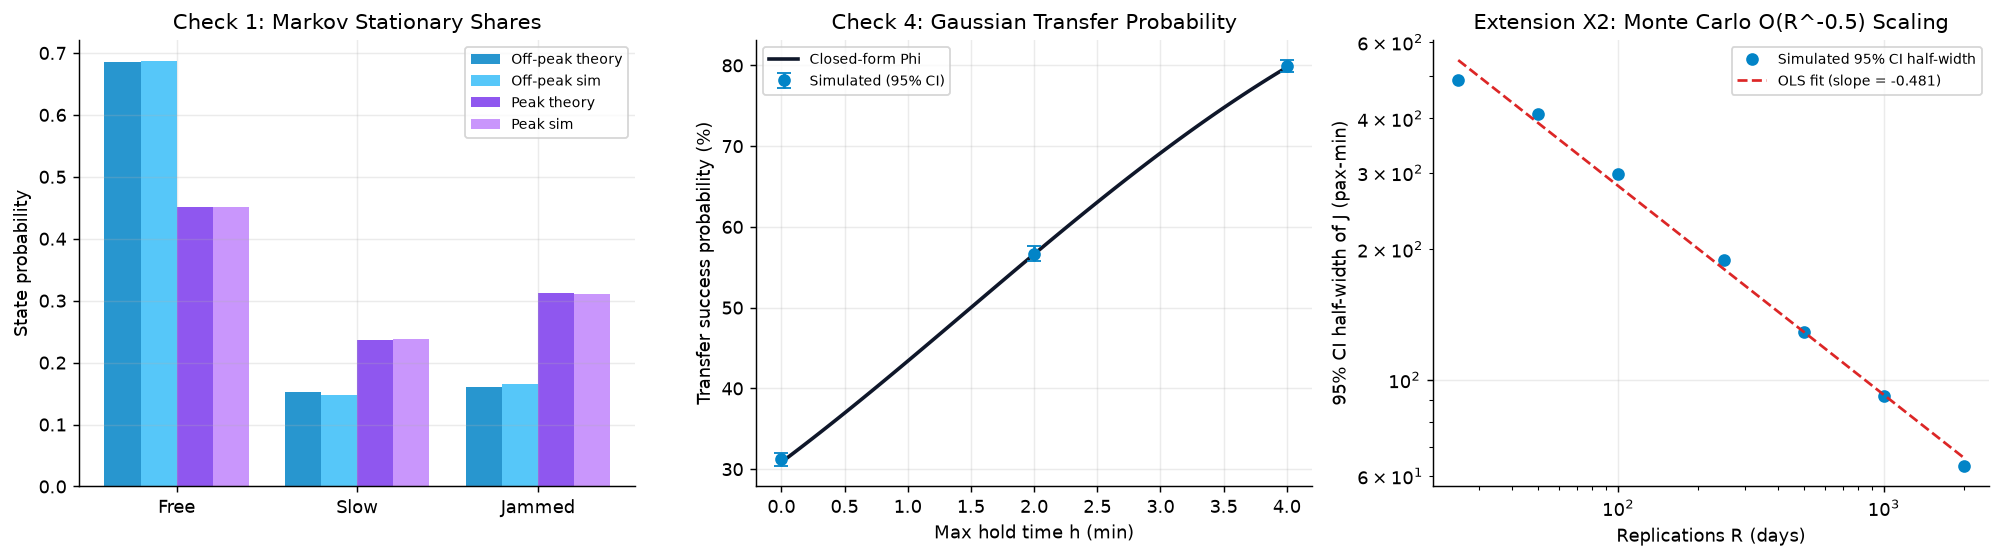

In [7]:
verify_seeds = root_seed_sequence.spawn(6)
verify_rng = np.random.default_rng(verify_seeds[0])
N_VERIFY_STEPS = 50_000

sim_shares_by_regime = {}
for label, P_mat, pi_star, target_v in [
    ("off-peak", P_offpeak, pi_offpeak, target_offpeak_kmph),
    ("peak", P_peak, pi_peak, target_peak_kmph),
]:
    states = simulate_markov_chain_loop(P_mat, N_VERIFY_STEPS, verify_rng)
    sim_shares = np.bincount(states, minlength=3) / N_VERIFY_STEPS
    sim_shares_by_regime[label] = (sim_shares, pi_star)
    max_share_diff = float(np.max(np.abs(sim_shares - pi_star)))
    assert max_share_diff < 0.015, f"{label} stationary mismatch: {max_share_diff:.4f}"

    sim_mean_speed = float(np.mean(STATE_SPEEDS_KMPH[states]))
    rel_speed_err = abs(sim_mean_speed - target_v) / target_v
    assert rel_speed_err < 0.02, f"{label} speed error {rel_speed_err:.4f} >= 2%"

    print(f"PASS [Check 1 & 2 - {label:8s}]: max |sim_share - pi*| = {max_share_diff:.4f} (< 0.015), "
          f"sim_speed = {sim_mean_speed:.2f} km/h vs target {target_v:.2f} km/h (rel err {rel_speed_err:.2%})")

runtime_check_days = [precompute_day_inputs(s) for s in verify_seeds[1].spawn(80)]
for leg_name in ROUTE_LEGS_CONFIG:
    assert LEG_CAL_REL_ERRORS[leg_name] < 0.02, f"{leg_name} calibration residual {LEG_CAL_REL_ERRORS[leg_name]:.4f} >= 2%"
    sched_rt = float((leg_schedules[leg_name]["borella_sched_min"] - leg_schedules[leg_name]["origin_sched_min"]).mean())
    daily_delays = np.array([d["leg_runs"][leg_name]["borella_delay_min"].mean() for d in runtime_check_days])
    mean_delay = float(np.mean(daily_delays))
    se_delay = float(np.std(daily_delays, ddof=1) / np.sqrt(len(daily_delays)))
    se_combined = float(np.std(daily_delays, ddof=1) * np.sqrt(1.0 / len(daily_delays) + 1.0 / N_CAL_DAYS))
    rel_rt_err = abs(mean_delay) / sched_rt
    assert abs(mean_delay) <= max(0.02 * sched_rt, 2.58 * se_combined), (
        f"{leg_name} verification runtime delay {mean_delay:.2f}m outside 99% combined CI (2.58*SE_comb={2.58*se_combined:.2f}m)"
    )
    print(f"  Check 2 [{leg_name}]: cal_err={LEG_CAL_REL_ERRORS[leg_name]:.2%}, test_delay={mean_delay:+.2f} +/- {1.96*se_delay:.2f}m (rel={rel_rt_err:.2%}, 99% comb lim={2.58*se_combined:.2f}m)")
print("PASS [Check 2 - leg calibration]: all 4 legs calibrated < 2% and test delays match scheduled runtime within Monte Carlo CI.")

det_feeders_df = pd.DataFrame([{"trip_id": "F1", "borella_arr_min": 500.0}])
det_conns_df = pd.DataFrame([{"trip_id": "C1", "borella_sched_min": 504.0, "borella_base_dep_min": 504.0, "borella_onboard_pax": 20}])
det_res = simulate_direction_transfers(
    det_feeders_df, det_conns_df, {"F1": "C1"}, {"F1": 10}, {"F1": 0.0},
    policy="none", hold_max_min=0.0, walk_time_min=3.5, capacity_pax=None
)
assert det_res["missed_total"] == 0 and det_res["made"] == 10, "Deterministic DES limiting case failed"
assert np.isclose(det_res["mean_wait_min"], 0.5), "Deterministic wait should equal offset - walk time"
print("PASS [Check 3 - zero-variance limit]: offset >= walk_time (uncapped) yields 0 missed transfers (P(miss) = 0.0) and wait = 0.5 min.")


def simulate_isolated_transfer_pairs(feeder_delays_min, connector_delays_min, offset_min, walk_min, policy, hold_max_min):
    n_pairs = len(feeder_delays_min)
    pair_start_min = 1000.0 * np.arange(n_pairs)
    feeder_ids = [f"F{i}" for i in range(n_pairs)]
    connector_ids = [f"C{i}" for i in range(n_pairs)]
    feeders_df = pd.DataFrame({"trip_id": feeder_ids, "borella_arr_min": pair_start_min + feeder_delays_min})
    connectors_df = pd.DataFrame({
        "trip_id": connector_ids,
        "borella_sched_min": pair_start_min + offset_min,
        "borella_base_dep_min": pair_start_min + offset_min + connector_delays_min,
        "borella_onboard_pax": 0,
    })
    res = simulate_direction_transfers(
        feeders_df, connectors_df, dict(zip(feeder_ids, connector_ids)),
        dict.fromkeys(feeder_ids, 1), dict.fromkeys(feeder_ids, 0.0),
        policy=policy, hold_max_min=hold_max_min, walk_time_min=walk_min, capacity_pax=None,
    )
    return res["made"] / n_pairs


gauss_rng = np.random.default_rng(verify_seeds[2])
N_GAUSS = 12_000
gaussian_check_rows = []
offset_min, walk_min = 4.0, 3.5
mu_f, sd_f = 2.0, 3.0
for h_val in (0.0, 2.0, 4.0):
    feeder_delays = np.array([mu_f + sd_f * sample_standard_normal_box_muller(gauss_rng) for _ in range(N_GAUSS)])
    p_sim = simulate_isolated_transfer_pairs(feeder_delays, np.zeros(N_GAUSS), offset_min, walk_min, "schedule", h_val)
    se = math.sqrt(p_sim * (1.0 - p_sim) / N_GAUSS)
    p_analytic = float(norm.cdf((offset_min + h_val - walk_min - mu_f) / sd_f))
    assert abs(p_sim - p_analytic) <= max(2.58 * se, 0.015), f"Gaussian check mismatch at h={h_val}"
    gaussian_check_rows.append({"label": f"One-sided h={h_val:.0f}m", "h": h_val, "p_sim": p_sim, "ci": 1.96 * se, "p_analytic": p_analytic})

mu_f2, sd_f2 = 12.0, 2.0
mu_c2, sd_c2 = 12.0, 2.0
offset_2, walk_2 = 5.0, 3.5
feeder_delays_2 = np.array([mu_f2 + sd_f2 * sample_standard_normal_box_muller(gauss_rng) for _ in range(N_GAUSS)])
connector_delays_2 = np.array([mu_c2 + sd_c2 * sample_standard_normal_box_muller(gauss_rng) for _ in range(N_GAUSS)])
p_sim_2 = simulate_isolated_transfer_pairs(feeder_delays_2, connector_delays_2, offset_2, walk_2, "none", 0.0)
se_2 = math.sqrt(p_sim_2 * (1.0 - p_sim_2) / N_GAUSS)
p_ana_2 = float(norm.cdf((offset_2 - walk_2 - (mu_f2 - mu_c2)) / math.sqrt(sd_f2**2 + sd_c2**2)))
assert abs(p_sim_2 - p_ana_2) <= max(2.58 * se_2, 0.015), "Two-sided Gaussian check mismatch"
gaussian_check_rows.append({"label": "Two-sided h=0m", "h": 0.0, "p_sim": p_sim_2, "ci": 1.96 * se_2, "p_analytic": p_ana_2})
gauss_df = pd.DataFrame(gaussian_check_rows)
print("PASS [Check 4 - Gaussian transfer probability (full event loop)]:")
print(gauss_df.round(4).to_string(index=False))

cons_streams = verify_seeds[3].spawn(3)
cons_traffic = generate_daily_traffic_grid(np.random.default_rng(cons_streams[0]), P_offpeak, P_peak)
cons_leg_df, cons_leg_stats = simulate_leg_day(
    "CM01_MAK_to_FOR",
    sched_cm01_mak,
    ROUTE_LEGS_CONFIG["CM01_MAK_to_FOR"],
    cons_traffic,
    np.random.default_rng(cons_streams[1]),
    np.random.default_rng(cons_streams[2]),
    capacity_pax=CAPACITY_PAX,
    alpha=LEG_ALPHAS["CM01_MAK_to_FOR"],
    return_stats=True,
)
assert cons_leg_stats["total_generated_stop_pax"] == (
    cons_leg_stats["total_boarded_pax"] + cons_leg_stats["end_of_day_unserved_pax"] + cons_leg_stats["abandoned_pax"]
)
assert cons_leg_stats["total_boarded_pax"] == cons_leg_stats["total_alighted_pax"]
assert cons_leg_stats["max_onboard_observed"] <= CAPACITY_PAX

check_day = precompute_day_inputs(verify_seeds[3])
for pol in ("none", "schedule", "realtime"):
    cons_out = evaluate_day(check_day, policy=pol, hold_max_min=3.0)
    for grp in ("A", "B"):
        g = cons_out[grp]
        accounted = g["made"] + g["missed_timing"] + g["missed_capacity"] + g["out_of_window"]
        assert accounted == g["total_generated"], f"Conservation failed for {pol} group {grp}"
        assert g["lost_timing"] <= g["missed_timing"] and g["lost_capacity"] <= g["missed_capacity"]
print("PASS [Check 5 - passenger conservation]: stop queues (boarded + unserved + abandoned) and all transfer outcomes conserved exactly.")

out_none = evaluate_day(check_day, policy="none", hold_max_min=0.0)
out_sched0 = evaluate_day(check_day, policy="schedule", hold_max_min=0.0)
out_rt0 = evaluate_day(check_day, policy="realtime", hold_max_min=0.0)
assert out_none == out_sched0 == out_rt0, "h=0 under schedule/realtime differs from none"
print("PASS [Check 6 - h=0 equivalence]: schedule(h=0) and realtime(h=0) match none identically.")

uncapped_df, uncapped_stats = simulate_leg_day(
    "CM03_KAD_to_MAK",
    sched_cm03_kad,
    ROUTE_LEGS_CONFIG["CM03_KAD_to_MAK"],
    cons_traffic,
    np.random.default_rng(cons_streams[1]),
    np.random.default_rng(cons_streams[2]),
    capacity_pax=None,
    alpha=LEG_ALPHAS["CM03_KAD_to_MAK"],
    return_stats=True,
)
assert uncapped_stats["total_left_behind_events"] == 0
uncapped_day = precompute_day_inputs(verify_seeds[3], capacity_pax=None)
uncapped_out = evaluate_day(uncapped_day, policy="schedule", hold_max_min=3.0, capacity_pax=None)
assert uncapped_out["A"]["missed_capacity"] == 0 and uncapped_out["B"]["missed_capacity"] == 0
print(f"PASS [Check 7 - capacity invariant]: capped max load = {cons_leg_stats['max_onboard_observed']} <= {CAPACITY_PAX}; uncapped produced 0 capacity misses.")

n_crn_test = 80
crn_seeds = verify_seeds[4].spawn(n_crn_test * 2)
paired_diffs, indep_diffs = [], []
for i in range(n_crn_test):
    d_a = precompute_day_inputs(crn_seeds[2 * i])
    d_b = precompute_day_inputs(crn_seeds[2 * i + 1])
    j0_a = evaluate_day(d_a, "none", 0.0)["A"]["total_cost"] + evaluate_day(d_a, "none", 0.0)["B"]["total_cost"]
    j3_a = evaluate_day(d_a, "schedule", 3.0)["A"]["total_cost"] + evaluate_day(d_a, "schedule", 3.0)["B"]["total_cost"]
    j3_b = evaluate_day(d_b, "schedule", 3.0)["A"]["total_cost"] + evaluate_day(d_b, "schedule", 3.0)["B"]["total_cost"]
    paired_diffs.append(j3_a - j0_a)
    indep_diffs.append(j3_b - j0_a)
var_paired = float(np.var(paired_diffs, ddof=1))
var_indep = float(np.var(indep_diffs, ddof=1))
assert var_paired < var_indep, f"CRN failed to reduce variance: {var_paired:.1f} >= {var_indep:.1f}"
print(f"PASS [Check 8 - CRN variance]: paired Var = {var_paired:.1f} < independent Var = {var_indep:.1f} ({100*(1 - var_paired/var_indep):.1f}% reduction).")

MAX_R_CONV = 2000
conv_seeds = verify_seeds[5].spawn(MAX_R_CONV)
PRECOMPUTED_POOL = [precompute_day_inputs(s) for s in conv_seeds]
pool_j_vals = np.array([evaluate_day(d, "realtime", 3.0)["A"]["total_cost"] + evaluate_day(d, "realtime", 3.0)["B"]["total_cost"] for d in PRECOMPUTED_POOL])
r_grid = np.array([25, 50, 100, 250, 500, 1000, 2000])
ci_halfwidths = np.array([1.96 * np.std(pool_j_vals[:r], ddof=1) / np.sqrt(r) for r in r_grid])
slope_loglog, intercept_loglog = np.polyfit(np.log10(r_grid), np.log10(ci_halfwidths), 1)
assert -0.60 <= slope_loglog <= -0.40, f"Monte Carlo scaling slope {slope_loglog:.3f} far from -0.5"
print(f"PASS [Extension X2 - MC error scaling]: log-log slope = {slope_loglog:.3f} (theoretical -0.500).")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

ax1 = axes[0]
x_idx = np.arange(3)
w_bar = 0.2
off_sim, off_pi = sim_shares_by_regime["off-peak"]
pk_sim, pk_pi = sim_shares_by_regime["peak"]
ax1.bar(x_idx - 1.5 * w_bar, off_pi, width=w_bar, color="#0284c7", alpha=0.85, label="Off-peak theory")
ax1.bar(x_idx - 0.5 * w_bar, off_sim, width=w_bar, color="#38bdf8", alpha=0.85, label="Off-peak sim")
ax1.bar(x_idx + 0.5 * w_bar, pk_pi, width=w_bar, color="#7c3aed", alpha=0.85, label="Peak theory")
ax1.bar(x_idx + 1.5 * w_bar, pk_sim, width=w_bar, color="#c084fc", alpha=0.85, label="Peak sim")
ax1.set_xticks(x_idx)
ax1.set_xticklabels(STATE_NAMES)
ax1.set_ylabel("State probability")
ax1.set_title("Check 1: Markov Stationary Shares")
ax1.legend(fontsize=8)

ax2 = axes[1]
one_sided = gauss_df[gauss_df["label"].str.startswith("One-sided")]
h_dense = np.linspace(0.0, 4.0, 80)
p_dense = norm.cdf((4.0 + h_dense - 3.5 - 2.0) / 3.0)
ax2.plot(h_dense, 100.0 * p_dense, color="#0f172a", linewidth=2, label="Closed-form Phi")
ax2.errorbar(one_sided["h"], 100.0 * one_sided["p_sim"], yerr=100.0 * one_sided["ci"], fmt="o", color="#0284c7", capsize=4, label="Simulated (95% CI)")
ax2.set_xlabel("Max hold time h (min)")
ax2.set_ylabel("Transfer success probability (%)")
ax2.set_title("Check 4: Gaussian Transfer Probability")
ax2.legend(fontsize=8)

ax3 = axes[2]
ax3.loglog(r_grid, ci_halfwidths, "o", color="#0284c7", label="Simulated 95% CI half-width")
ax3.loglog(r_grid, 10**(intercept_loglog + slope_loglog * np.log10(r_grid)), "--", color="#dc2626", label=f"OLS fit (slope = {slope_loglog:.3f})")
ax3.set_xlabel("Replications R (days)")
ax3.set_ylabel("95% CI half-width of J (pax-min)")
ax3.set_title("Extension X2: Monte Carlo O(R^-0.5) Scaling")
ax3.legend(fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "verification.png", bbox_inches="tight")
plt.show()

## 5. Experiments and results

*Provenance: AI-generated.*

We conduct five structured experiments using common random numbers across identical simulated days:

- **E1 (Baseline diagnosis, $R = 1000$):** Quantify missed timing vs missed capacity rates, mean transfer wait times, and objective cost $J(0, 0)$ on the published timetable without holding.
- **E2 (Holding sweep, $h \in [0, 6]\text{ min}$, $R = 400$):** Compare `schedule` vs `realtime` holding at the current timetable ($\Delta = 0$).
- **E3 (Timetable shift and joint optimization, $\Delta \in [-30, +30]\text{ min}$, $R = 200$):** Evaluate shifting CM03 (and CM01) across both directions simultaneously with holding $h \in [0, 6]\text{ min}$ to find the joint optimum $(h^*, \Delta^*)$.
- **E4 (Stretch goal X3 - ETA prediction noise, $R = 500$):** Test how real-time ETA holding performs against schedule-based holding as GPS prediction error $\sigma_{\text{eta}}$ grows from $0$ to $4\text{ min}$.
- **E6 (Ticket validity, $R = 1000$):** Distribution of Borella transfer waits for boarded through-ticket passengers, compared with the proposed 2-hour validity of the part-paid ticket.
- **E5 & Extensions X5/X6:** Isolate the capacity bottleneck ($C=80$ vs $C=\infty$), run a multi-parameter sensitivity tornado + 2D grid analysis, and benchmark vectorized vs loop Markov traffic generation.

=== E1: Current Timetable Baseline Diagnosis (R = 1000 CRN days, 95% CI) ===
    Miss A (%)     Miss B (%)   Miss All (%)  Timing Miss (%)  Cap Miss (%)       Lost (%)  Wait p95 (min) Mean Wait (min)     J (pax-min)
34.02 +/- 1.09 18.49 +/- 0.80 25.08 +/- 0.67            21.54          3.54 15.51 +/- 0.55            80.4  37.31 +/- 0.39 9502.2 +/- 93.1



=== E2: Borella Holding Sweep at Current Timetable (R = 400 CRN days) ===
 h_min  sched_miss_A  sched_miss_B  sched_miss_all  sched_hold_cost  sched_J  rt_miss_all  rt_hold_cost    rt_J
   0.0         34.43         17.93           24.95             0.00  9501.47        24.95          0.00 9501.47
   0.5         33.57         17.59           24.39            61.81  9505.23        24.66          1.94 9469.40
   1.0         32.90         17.13           23.83           121.97  9505.31        24.22          4.89 9423.20
   1.5         32.27         16.91           23.44           180.53  9524.40        23.84          8.75 9383.33
   2.0         31.30         16.46           22.79           237.33  9511.79        23.29         16.30 9329.95
   2.5         30.39         16.16           22.25           292.25  9510.88        22.76         24.80 9280.28
   3.0         29.29         15.79           21.57           345.53  9493.24        22.09         37.56 9218.78
   3.5         28.13         

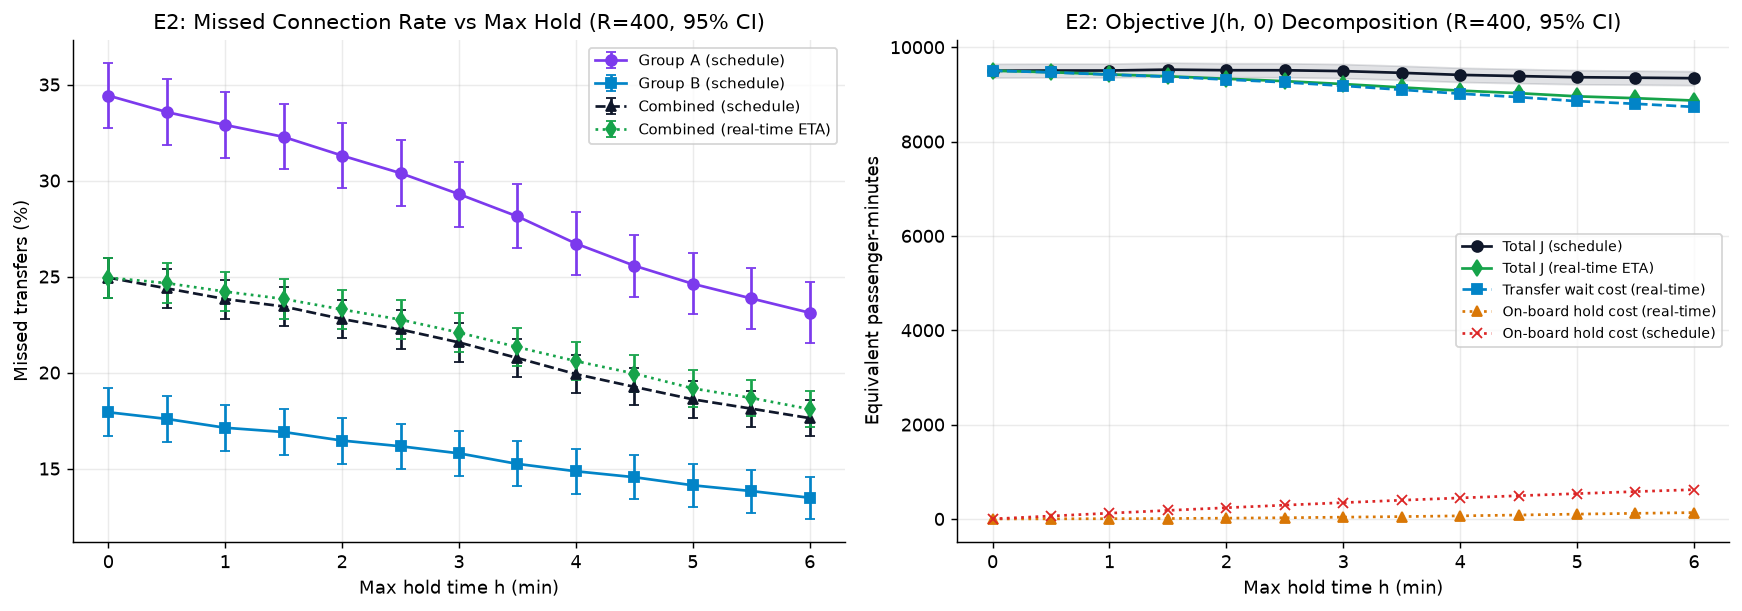

In [8]:
def summarize_ci(values):
    arr = np.asarray(values, dtype=float)
    mean_val = float(np.mean(arr))
    ci_half = 1.96 * float(np.std(arr, ddof=1)) / np.sqrt(len(arr))
    return mean_val, ci_half


def evaluate_policy_over_days(days_pool, policy, hold_max_min, walk_time_min=WALK_TIME_PLACEHOLDER_MIN, capacity_pax=CAPACITY_PAX, wait_weight=WAIT_WEIGHT, hold_weight=HOLD_WEIGHT):
    miss_a, miss_b, miss_all = [], [], []
    lost_all, boarded_waits = [], []
    miss_timing_all, miss_cap_all = [], []
    wait_min_all, j_all, wait_cost_all, hold_cost_all = [], [], [], []

    for day_in in days_pool:
        res = evaluate_day(
            day_in,
            policy=policy,
            hold_max_min=hold_max_min,
            walk_time_min=walk_time_min,
            capacity_pax=capacity_pax,
            wait_weight=wait_weight,
            hold_weight=hold_weight,
        )
        a_in = max(1, res["A"]["in_window_total"])
        b_in = max(1, res["B"]["in_window_total"])
        tot_in = max(1, res["A"]["in_window_total"] + res["B"]["in_window_total"])

        miss_a.append(100.0 * res["A"]["missed_total"] / a_in)
        miss_b.append(100.0 * res["B"]["missed_total"] / b_in)
        miss_timing_all.append(100.0 * (res["A"]["missed_timing"] + res["B"]["missed_timing"]) / tot_in)
        miss_cap_all.append(100.0 * (res["A"]["missed_capacity"] + res["B"]["missed_capacity"]) / tot_in)
        miss_all.append(100.0 * (res["A"]["missed_total"] + res["B"]["missed_total"]) / tot_in)
        wait_min_all.append((res["A"]["total_wait_min"] + res["B"]["total_wait_min"]) / tot_in)
        wait_cost_all.append(res["A"]["wait_cost"] + res["B"]["wait_cost"])
        hold_cost_all.append(res["A"]["hold_cost"] + res["B"]["hold_cost"])
        j_all.append(res["A"]["total_cost"] + res["B"]["total_cost"])
        lost_all.append(100.0 * (res["A"]["lost_total"] + res["B"]["lost_total"]) / tot_in)
        boarded_waits.extend(res["A"]["boarded_wait_mins"])
        boarded_waits.extend(res["B"]["boarded_wait_mins"])

    ma_m, ma_ci = summarize_ci(miss_a)
    mb_m, mb_ci = summarize_ci(miss_b)
    mall_m, mall_ci = summarize_ci(miss_all)
    mt_m, _ = summarize_ci(miss_timing_all)
    mc_m, _ = summarize_ci(miss_cap_all)
    wm_m, wm_ci = summarize_ci(wait_min_all)
    wc_m, _ = summarize_ci(wait_cost_all)
    hc_m, _ = summarize_ci(hold_cost_all)
    j_m, j_ci = summarize_ci(j_all)
    lost_m, lost_ci = summarize_ci(lost_all)
    waits_arr = np.asarray(boarded_waits, dtype=float)
    return {
        "miss_A_pct": ma_m, "miss_A_ci": ma_ci,
        "miss_B_pct": mb_m, "miss_B_ci": mb_ci,
        "miss_all_pct": mall_m, "miss_all_ci": mall_ci,
        "miss_timing_pct": mt_m, "miss_cap_pct": mc_m,
        "mean_wait_min": wm_m, "mean_wait_ci": wm_ci,
        "wait_cost": wc_m, "hold_cost": hc_m,
        "J_mean": j_m, "J_ci": j_ci,
        "lost_pct": lost_m, "lost_ci": lost_ci,
        "wait_p95_min": float(np.percentile(waits_arr, 95)) if waits_arr.size else float("nan"),
        "boarded_waits": waits_arr,
    }


R_FINAL = 1000
FINAL_POOL = PRECOMPUTED_POOL[:R_FINAL]
base_summary = evaluate_policy_over_days(FINAL_POOL, "none", 0.0)

print(f"=== E1: Current Timetable Baseline Diagnosis (R = {R_FINAL} CRN days, 95% CI) ===")
e1_table = pd.DataFrame([{
    "Miss A (%)": f"{base_summary['miss_A_pct']:.2f} +/- {base_summary['miss_A_ci']:.2f}",
    "Miss B (%)": f"{base_summary['miss_B_pct']:.2f} +/- {base_summary['miss_B_ci']:.2f}",
    "Miss All (%)": f"{base_summary['miss_all_pct']:.2f} +/- {base_summary['miss_all_ci']:.2f}",
    "Timing Miss (%)": round(base_summary["miss_timing_pct"], 2),
    "Cap Miss (%)": round(base_summary["miss_cap_pct"], 2),
    "Lost (%)": f"{base_summary['lost_pct']:.2f} +/- {base_summary['lost_ci']:.2f}",
    "Wait p95 (min)": round(base_summary["wait_p95_min"], 1),
    "Mean Wait (min)": f"{base_summary['mean_wait_min']:.2f} +/- {base_summary['mean_wait_ci']:.2f}",
    "J (pax-min)": f"{base_summary['J_mean']:.1f} +/- {base_summary['J_ci']:.1f}",
}])
print(e1_table.to_string(index=False))

R_SWEEP = 400
SWEEP_POOL = PRECOMPUTED_POOL[:R_SWEEP]
HOLD_GRID_MIN = np.arange(0.0, 6.5, 0.5)

e2_rows = []
for h_val in HOLD_GRID_MIN:
    pol_s = "none" if h_val == 0.0 else "schedule"
    pol_r = "none" if h_val == 0.0 else "realtime"
    s_res = evaluate_policy_over_days(SWEEP_POOL, pol_s, float(h_val))
    r_res = evaluate_policy_over_days(SWEEP_POOL, pol_r, float(h_val))
    e2_rows.append({
        "h_min": float(h_val),
        "sched_miss_A": s_res["miss_A_pct"], "sched_miss_A_ci": s_res["miss_A_ci"],
        "sched_miss_B": s_res["miss_B_pct"], "sched_miss_B_ci": s_res["miss_B_ci"],
        "sched_miss_all": s_res["miss_all_pct"], "sched_miss_all_ci": s_res["miss_all_ci"],
        "sched_wait_cost": s_res["wait_cost"], "sched_hold_cost": s_res["hold_cost"],
        "sched_J": s_res["J_mean"], "sched_J_ci": s_res["J_ci"],
        "rt_miss_all": r_res["miss_all_pct"], "rt_miss_all_ci": r_res["miss_all_ci"],
        "rt_wait_cost": r_res["wait_cost"], "rt_hold_cost": r_res["hold_cost"],
        "rt_J": r_res["J_mean"], "rt_J_ci": r_res["J_ci"],
    })

e2_df = pd.DataFrame(e2_rows)
print(f"\n=== E2: Borella Holding Sweep at Current Timetable (R = {R_SWEEP} CRN days) ===")
print(e2_df[["h_min", "sched_miss_A", "sched_miss_B", "sched_miss_all", "sched_hold_cost", "sched_J", "rt_miss_all", "rt_hold_cost", "rt_J"]].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

ax1 = axes[0]
ax1.errorbar(e2_df["h_min"], e2_df["sched_miss_A"], yerr=e2_df["sched_miss_A_ci"], marker="o", capsize=3, color="#7c3aed", label="Group A (schedule)")
ax1.errorbar(e2_df["h_min"], e2_df["sched_miss_B"], yerr=e2_df["sched_miss_B_ci"], marker="s", capsize=3, color="#0284c7", label="Group B (schedule)")
ax1.errorbar(e2_df["h_min"], e2_df["sched_miss_all"], yerr=e2_df["sched_miss_all_ci"], marker="^", linestyle="--", capsize=3, color="#0f172a", label="Combined (schedule)")
ax1.errorbar(e2_df["h_min"], e2_df["rt_miss_all"], yerr=e2_df["rt_miss_all_ci"], marker="d", linestyle=":", capsize=3, color="#16a34a", label="Combined (real-time ETA)")
ax1.set_xlabel("Max hold time h (min)")
ax1.set_ylabel("Missed transfers (%)")
ax1.set_title(f"E2: Missed Connection Rate vs Max Hold (R={R_SWEEP}, 95% CI)")
ax1.legend(fontsize=8.5)

ax2 = axes[1]
ax2.plot(e2_df["h_min"], e2_df["sched_J"], marker="o", color="#0f172a", label="Total J (schedule)")
ax2.fill_between(e2_df["h_min"], e2_df["sched_J"] - e2_df["sched_J_ci"], e2_df["sched_J"] + e2_df["sched_J_ci"], color="#0f172a", alpha=0.12)
ax2.plot(e2_df["h_min"], e2_df["rt_J"], marker="d", color="#16a34a", label="Total J (real-time ETA)")
ax2.plot(e2_df["h_min"], e2_df["rt_wait_cost"], marker="s", linestyle="--", color="#0284c7", label="Transfer wait cost (real-time)")
ax2.plot(e2_df["h_min"], e2_df["rt_hold_cost"], marker="^", linestyle=":", color="#d97706", label="On-board hold cost (real-time)")
ax2.plot(e2_df["h_min"], e2_df["sched_hold_cost"], marker="x", linestyle=":", color="#dc2626", label="On-board hold cost (schedule)")
ax2.set_xlabel("Max hold time h (min)")
ax2.set_ylabel("Equivalent passenger-minutes")
ax2.set_title(f"E2: Objective J(h, 0) Decomposition (R={R_SWEEP}, 95% CI)")
ax2.legend(fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "holding_sweep.png", bbox_inches="tight")
plt.show()

Route shift comparison at h=3.0m (realtime): best CM03 J=8996.4, best CM01 J=8982.2 -> focusing 2D grid on CM01



=== E3: Top 8 Joint (CM01 Shift Delta, Real-Time Hold h) Policies (R = 200) ===
 delta_min  h_min  miss_A_pct  miss_B_pct  miss_all_pct  J_mean   J_ci
       5.0    6.0       17.15       13.31         14.96 8585.19 195.07
       5.0    5.0       18.43       13.71         15.72 8642.58 193.83
      10.0    6.0       13.11       19.91         17.19 8743.38 184.51
       5.0    4.0       19.81       14.69         16.86 8745.34 194.28
       0.0    6.0       24.86       14.65         19.09 8837.65 185.30
       5.0    3.0       20.72       16.01         18.01 8855.04 194.02
      10.0    5.0       14.09       21.71         18.62 8868.79 191.63
       0.0    5.0       26.19       15.09         19.86 8889.97 186.57


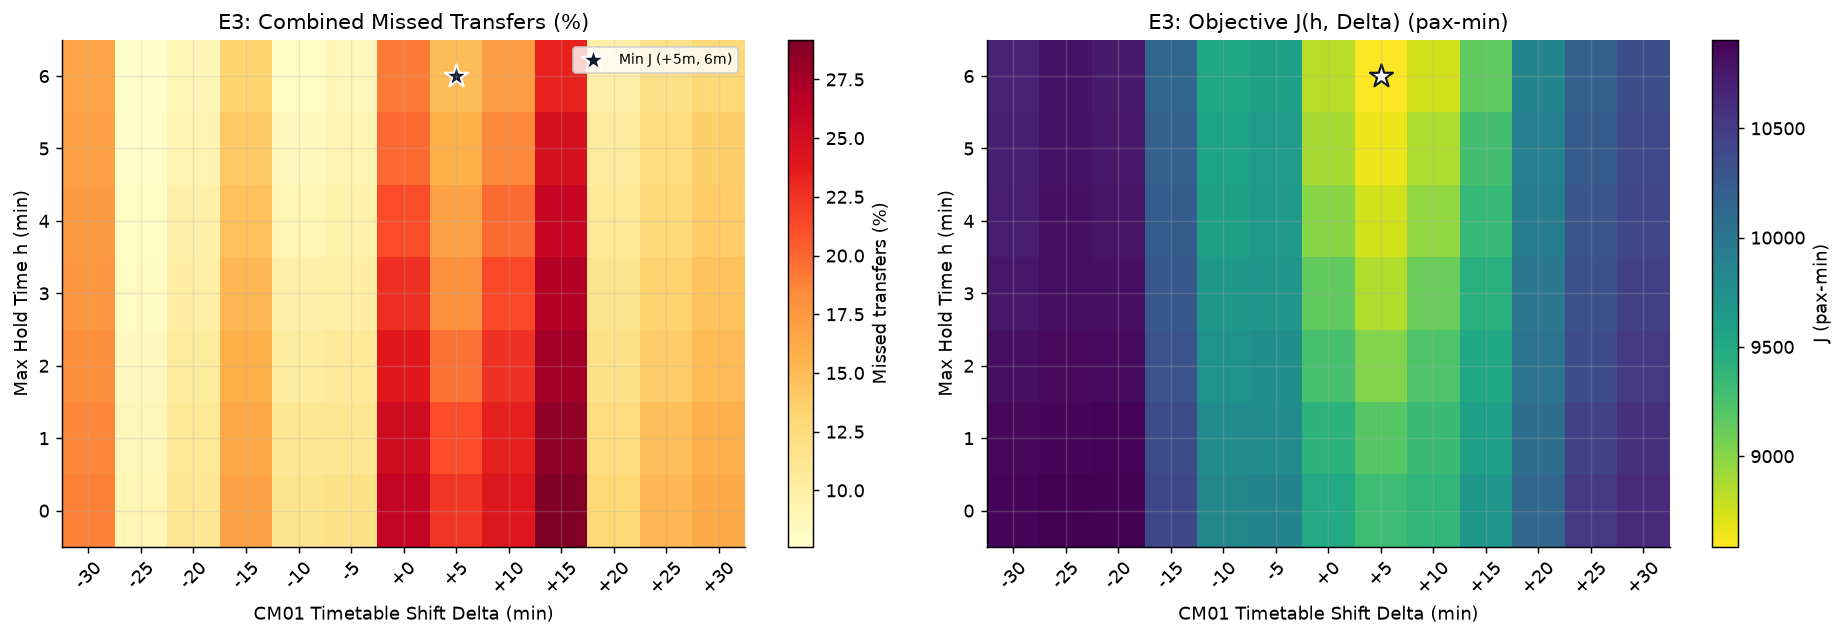


=== E4: Real-Time ETA Holding vs Schedule Holding at Optimal Shift (Delta=+5m, h=6.0m, R=500) ===
           policy_mode  eta_noise_sd_min  miss_all_pct  hold_cost_pax_min  J_mean   J_ci
schedule (no ETA skip)               0.0         14.81             529.60 9020.78 145.01
  realtime ETA holding               0.0         14.88             120.61 8607.21 130.95
  realtime ETA holding               1.0         15.61             115.00 8659.36 123.91
  realtime ETA holding               2.0         15.47             117.67 8708.52 126.98
  realtime ETA holding               4.0         16.12             124.50 8731.67 123.31



=== Consolidated Policy Comparison (R = 1000 CRN days, 95% CI) ===
                  Scenario     Miss A (%)     Miss B (%)   Miss All (%)       Lost (%) Mean Wait (min)  Wait p95 (min)  Hold Cost     J (pax-min)
  Baseline (current, none) 34.02 +/- 1.05 17.90 +/- 0.78 24.70 +/- 0.64 15.11 +/- 0.54  36.92 +/- 0.37            80.4        0.0 9392.5 +/- 94.4
Hold only (schedule, h=3m) 29.08 +/- 1.01 15.39 +/- 0.73 21.14 +/- 0.60 11.93 +/- 0.49  34.98 +/- 0.37            79.7      351.9 9381.1 +/- 97.7
Hold only (realtime, h=3m) 29.72 +/- 1.02 15.77 +/- 0.74 21.63 +/- 0.61 12.37 +/- 0.50  35.12 +/- 0.37            79.7       33.9 9090.2 +/- 95.1
     Shift only (CM01 +5m) 24.99 +/- 1.03 21.47 +/- 0.79 22.97 +/- 0.62 15.99 +/- 0.53  36.91 +/- 0.38            79.0        0.0 9384.8 +/- 91.7
Joint schedule (h=6m, +5m) 17.37 +/- 0.92 13.14 +/- 0.65 14.93 +/- 0.53  8.47 +/- 0.41  32.24 +/- 0.39            77.3      543.2 9043.2 +/- 96.6
Joint realtime (h=6m, +5m) 17.79 +/- 0.93 13.58 +/- 0.66

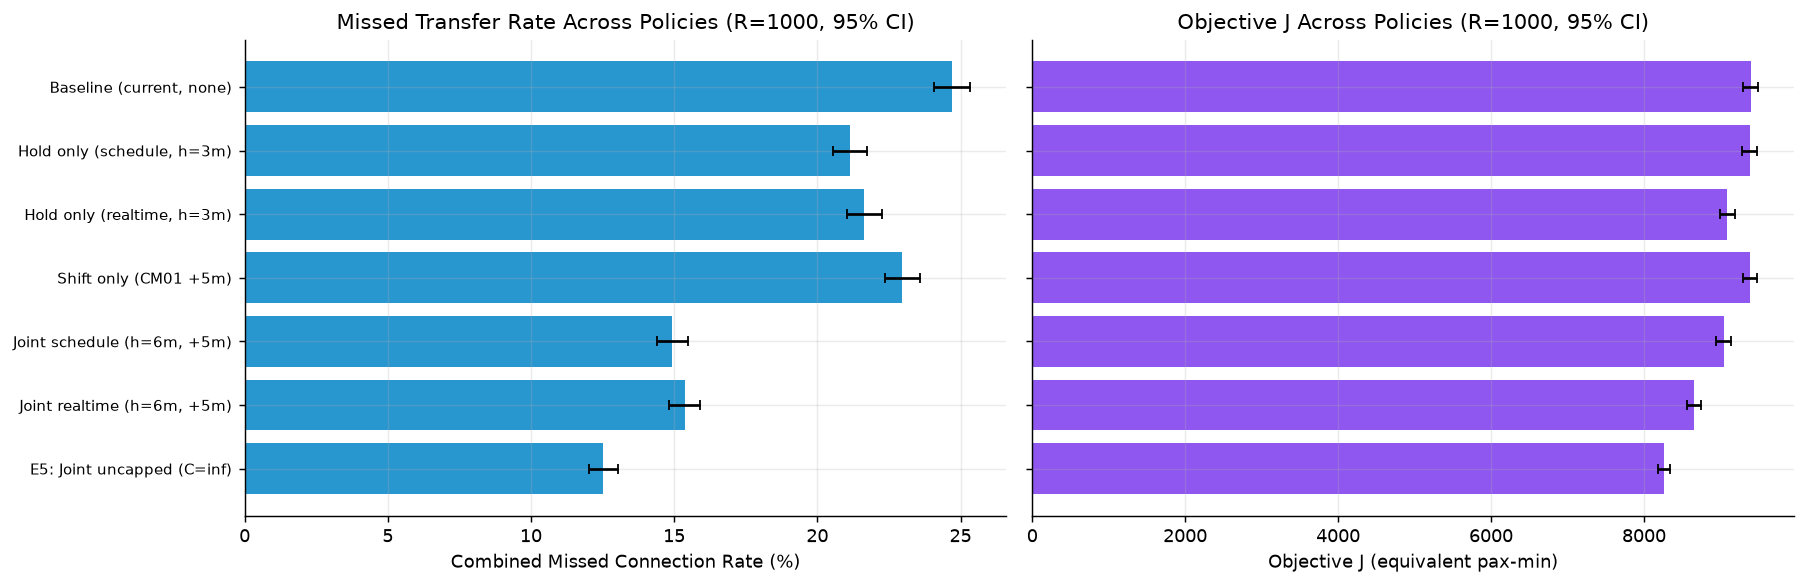

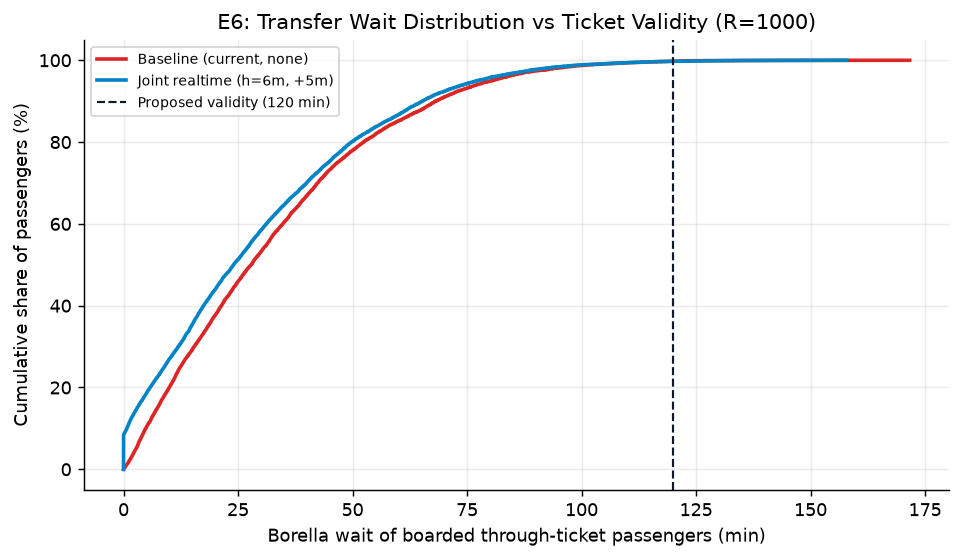


=== E6: Through-Ticket Validity at Borella (R = 1000 CRN days) ===
                  Scenario  Median wait (min)  p90 wait (min)  p95 wait (min)  Max wait (min)  Within 120 min (%)
  Baseline (current, none)               27.9            68.2            80.4           171.6               99.78
Joint realtime (h=6m, +5m)               24.0            65.3            77.3           157.9               99.75


In [9]:
R_GRID = 200
SHIFT_VALUES_MIN = np.arange(-30.0, 35.0, 5.0)
HOLD_GRID_COARSE_MIN = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0])
grid_seeds = root_seed_sequence.spawn(R_GRID)

route_comp_rows = []
for delta in SHIFT_VALUES_MIN:
    days_cm03 = [precompute_day_inputs(s, shift_cm03_min=float(delta)) for s in grid_seeds]
    days_cm01 = [precompute_day_inputs(s, shift_cm01_min=float(delta)) for s in grid_seeds]
    s03 = evaluate_policy_over_days(days_cm03, "realtime", 3.0)
    s01 = evaluate_policy_over_days(days_cm01, "realtime", 3.0)
    route_comp_rows.append({
        "delta_min": float(delta),
        "cm03_shift_miss_pct": s03["miss_all_pct"],
        "cm03_shift_J": s03["J_mean"],
        "cm01_shift_miss_pct": s01["miss_all_pct"],
        "cm01_shift_J": s01["J_mean"],
    })

route_comp_df = pd.DataFrame(route_comp_rows)
best_cm03_j = route_comp_df["cm03_shift_J"].min()
best_cm01_j = route_comp_df["cm01_shift_J"].min()
shift_target_route = "CM03" if best_cm03_j <= best_cm01_j else "CM01"
print(f"Route shift comparison at h=3.0m (realtime): best CM03 J={best_cm03_j:.1f}, best CM01 J={best_cm01_j:.1f} -> focusing 2D grid on {shift_target_route}")

miss_grid = np.zeros((len(HOLD_GRID_COARSE_MIN), len(SHIFT_VALUES_MIN)))
j_grid = np.zeros((len(HOLD_GRID_COARSE_MIN), len(SHIFT_VALUES_MIN)))
grid_records = []

for c_idx, delta in enumerate(SHIFT_VALUES_MIN):
    shift_kw = {"shift_cm03_min": float(delta)} if shift_target_route == "CM03" else {"shift_cm01_min": float(delta)}
    days_delta = [precompute_day_inputs(s, **shift_kw) for s in grid_seeds]
    for r_idx, h_val in enumerate(HOLD_GRID_COARSE_MIN):
        pol = "none" if h_val == 0.0 else "realtime"
        res = evaluate_policy_over_days(days_delta, pol, float(h_val))
        miss_grid[r_idx, c_idx] = res["miss_all_pct"]
        j_grid[r_idx, c_idx] = res["J_mean"]
        grid_records.append({
            "delta_min": float(delta),
            "h_min": float(h_val),
            "miss_A_pct": res["miss_A_pct"],
            "miss_B_pct": res["miss_B_pct"],
            "miss_all_pct": res["miss_all_pct"],
            "J_mean": res["J_mean"],
            "J_ci": res["J_ci"],
        })

grid_df = pd.DataFrame(grid_records)
opt_idx = int(grid_df["J_mean"].idxmin())
OPT_DELTA_MIN = float(grid_df.loc[opt_idx, "delta_min"])
OPT_H_MIN = float(grid_df.loc[opt_idx, "h_min"])

print(f"\n=== E3: Top 8 Joint ({shift_target_route} Shift Delta, Real-Time Hold h) Policies (R = {R_GRID}) ===")
print(grid_df.sort_values("J_mean").head(8).round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))
opt_r = int(np.where(HOLD_GRID_COARSE_MIN == OPT_H_MIN)[0][0])
opt_c = int(np.where(SHIFT_VALUES_MIN == OPT_DELTA_MIN)[0][0])

im1 = axes[0].imshow(miss_grid, aspect="auto", origin="lower", cmap="YlOrRd")
axes[0].set_xticks(range(len(SHIFT_VALUES_MIN)))
axes[0].set_xticklabels([f"{int(d):+d}" for d in SHIFT_VALUES_MIN], rotation=45)
axes[0].set_yticks(range(len(HOLD_GRID_COARSE_MIN)))
axes[0].set_yticklabels([f"{h:.0f}" for h in HOLD_GRID_COARSE_MIN])
axes[0].set_xlabel(f"{shift_target_route} Timetable Shift Delta (min)")
axes[0].set_ylabel("Max Hold Time h (min)")
axes[0].set_title("E3: Combined Missed Transfers (%)")
axes[0].scatter([opt_c], [opt_r], marker="*", s=180, color="#0f172a", edgecolor="#ffffff", linewidth=1.2, label=f"Min J ({OPT_DELTA_MIN:+.0f}m, {OPT_H_MIN:.0f}m)")
axes[0].legend(loc="upper right", fontsize=8)
plt.colorbar(im1, ax=axes[0], label="Missed transfers (%)")

im2 = axes[1].imshow(j_grid, aspect="auto", origin="lower", cmap="viridis_r")
axes[1].set_xticks(range(len(SHIFT_VALUES_MIN)))
axes[1].set_xticklabels([f"{int(d):+d}" for d in SHIFT_VALUES_MIN], rotation=45)
axes[1].set_yticks(range(len(HOLD_GRID_COARSE_MIN)))
axes[1].set_yticklabels([f"{h:.0f}" for h in HOLD_GRID_COARSE_MIN])
axes[1].set_xlabel(f"{shift_target_route} Timetable Shift Delta (min)")
axes[1].set_ylabel("Max Hold Time h (min)")
axes[1].set_title("E3: Objective J(h, Delta) (pax-min)")
axes[1].scatter([opt_c], [opt_r], marker="*", s=180, color="#ffffff", edgecolor="#0f172a", linewidth=1.2)
plt.colorbar(im2, ax=axes[1], label="J (pax-min)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "timetable_shift_heatmap.png", bbox_inches="tight")
plt.show()

R_E4 = 500
e4_seeds = root_seed_sequence.spawn(R_E4)
opt_shift_kw = {"shift_cm03_min": OPT_DELTA_MIN} if shift_target_route == "CM03" else {"shift_cm01_min": OPT_DELTA_MIN}
e4_rows = []
days_opt_base = [precompute_day_inputs(s, **opt_shift_kw, eta_noise_sd_min=0.0) for s in e4_seeds]
sched_opt_eval = evaluate_policy_over_days(days_opt_base, "schedule", max(1.0, OPT_H_MIN))
e4_rows.append({
    "policy_mode": "schedule (no ETA skip)",
    "eta_noise_sd_min": 0.0,
    "miss_all_pct": sched_opt_eval["miss_all_pct"],
    "hold_cost_pax_min": sched_opt_eval["hold_cost"],
    "J_mean": sched_opt_eval["J_mean"],
    "J_ci": sched_opt_eval["J_ci"],
})
for sigma_eta in (0.0, 1.0, 2.0, 4.0):
    days_rt = [precompute_day_inputs(s, **opt_shift_kw, eta_noise_sd_min=sigma_eta) for s in e4_seeds]
    rt_eval = evaluate_policy_over_days(days_rt, "realtime", max(1.0, OPT_H_MIN))
    e4_rows.append({
        "policy_mode": "realtime ETA holding",
        "eta_noise_sd_min": sigma_eta,
        "miss_all_pct": rt_eval["miss_all_pct"],
        "hold_cost_pax_min": rt_eval["hold_cost"],
        "J_mean": rt_eval["J_mean"],
        "J_ci": rt_eval["J_ci"],
    })
print(f"\n=== E4: Real-Time ETA Holding vs Schedule Holding at Optimal Shift (Delta={OPT_DELTA_MIN:+.0f}m, h={max(1.0, OPT_H_MIN):.1f}m, R={R_E4}) ===")
print(pd.DataFrame(e4_rows).round(2).to_string(index=False))

final_seeds = root_seed_sequence.spawn(R_FINAL)
final_opt_days = [precompute_day_inputs(s, **opt_shift_kw) for s in final_seeds]
final_uncapped_days = [precompute_day_inputs(s, **opt_shift_kw, capacity_pax=None) for s in final_seeds]
final_base_days = [precompute_day_inputs(s) for s in final_seeds]

policy_specs = [
    ("Baseline (current, none)", final_base_days, "none", 0.0, CAPACITY_PAX),
    ("Hold only (schedule, h=3m)", final_base_days, "schedule", 3.0, CAPACITY_PAX),
    ("Hold only (realtime, h=3m)", final_base_days, "realtime", 3.0, CAPACITY_PAX),
    (f"Shift only ({shift_target_route} {OPT_DELTA_MIN:+.0f}m)", final_opt_days, "none", 0.0, CAPACITY_PAX),
    (f"Joint schedule (h={OPT_H_MIN:.0f}m, {OPT_DELTA_MIN:+.0f}m)", final_opt_days, "none" if OPT_H_MIN == 0 else "schedule", OPT_H_MIN, CAPACITY_PAX),
    (f"Joint realtime (h={OPT_H_MIN:.0f}m, {OPT_DELTA_MIN:+.0f}m)", final_opt_days, "none" if OPT_H_MIN == 0 else "realtime", OPT_H_MIN, CAPACITY_PAX),
    (f"E5: Joint uncapped (C=inf)", final_uncapped_days, "none" if OPT_H_MIN == 0 else "realtime", OPT_H_MIN, None),
]

final_rows = []
scenario_waits = {}
for label, pool, pol, h_v, cap in policy_specs:
    s = evaluate_policy_over_days(pool, pol, h_v, capacity_pax=cap)
    final_rows.append({
        "Scenario": label,
        "Miss A (%)": f"{s['miss_A_pct']:.2f} +/- {s['miss_A_ci']:.2f}",
        "Miss B (%)": f"{s['miss_B_pct']:.2f} +/- {s['miss_B_ci']:.2f}",
        "Miss All (%)": f"{s['miss_all_pct']:.2f} +/- {s['miss_all_ci']:.2f}",
        "Mean Wait (min)": f"{s['mean_wait_min']:.2f} +/- {s['mean_wait_ci']:.2f}",
        "Hold Cost": round(s["hold_cost"], 1),
        "Lost (%)": f"{s['lost_pct']:.2f} +/- {s['lost_ci']:.2f}",
        "Wait p95 (min)": round(s["wait_p95_min"], 1),
        "J (pax-min)": f"{s['J_mean']:.1f} +/- {s['J_ci']:.1f}",
        "_miss_val": s["miss_all_pct"],
        "_miss_ci": s["miss_all_ci"],
        "_j_val": s["J_mean"],
        "_j_ci": s["J_ci"],
    })
    scenario_waits[label] = s["boarded_waits"]

final_comp_df = pd.DataFrame(final_rows)
print(f"\n=== Consolidated Policy Comparison (R = {R_FINAL} CRN days, 95% CI) ===")
print(final_comp_df[["Scenario", "Miss A (%)", "Miss B (%)", "Miss All (%)", "Lost (%)", "Mean Wait (min)", "Wait p95 (min)", "Hold Cost", "J (pax-min)"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.6))
y_pos = np.arange(len(final_comp_df))
axes[0].barh(y_pos, final_comp_df["_miss_val"], xerr=final_comp_df["_miss_ci"], color="#0284c7", alpha=0.85, capsize=3)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(final_comp_df["Scenario"], fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Combined Missed Connection Rate (%)")
axes[0].set_title(f"Missed Transfer Rate Across Policies (R={R_FINAL}, 95% CI)")

axes[1].barh(y_pos, final_comp_df["_j_val"], xerr=final_comp_df["_j_ci"], color="#7c3aed", alpha=0.85, capsize=3)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([])
axes[1].invert_yaxis()
axes[1].set_xlabel("Objective J (equivalent pax-min)")
axes[1].set_title(f"Objective J Across Policies (R={R_FINAL}, 95% CI)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "policy_comparison.png", bbox_inches="tight")
plt.show()


validity_scenarios = [(policy_specs[0][0], "#dc2626"), (policy_specs[5][0], "#0284c7")]
validity_rows = []
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for scenario_label, line_color in validity_scenarios:
    waits = np.sort(scenario_waits[scenario_label])
    ax.plot(waits, 100.0 * np.arange(1, len(waits) + 1) / len(waits), color=line_color, linewidth=2, label=scenario_label)
    validity_rows.append({
        "Scenario": scenario_label,
        "Median wait (min)": round(float(np.median(waits)), 1),
        "p90 wait (min)": round(float(np.percentile(waits, 90)), 1),
        "p95 wait (min)": round(float(np.percentile(waits, 95)), 1),
        "Max wait (min)": round(float(np.max(waits)), 1),
        f"Within {TICKET_VALIDITY_MIN:.0f} min (%)": round(100.0 * float(np.mean(waits <= TICKET_VALIDITY_MIN)), 2),
    })
ax.axvline(TICKET_VALIDITY_MIN, color="#0f172a", linestyle="--", linewidth=1.2, label=f"Proposed validity ({TICKET_VALIDITY_MIN:.0f} min)")
ax.set_xlabel("Borella wait of boarded through-ticket passengers (min)")
ax.set_ylabel("Cumulative share of passengers (%)")
ax.set_title(f"E6: Transfer Wait Distribution vs Ticket Validity (R={R_FINAL})")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "ticket_validity.png", bbox_inches="tight")
plt.show()

print(f"\n=== E6: Through-Ticket Validity at Borella (R = {R_FINAL} CRN days) ===")
print(pd.DataFrame(validity_rows).to_string(index=False))


=== Extension X5: Sensitivity Analysis around Joint Optimal Policy (Base J = 8824.8, R = 250) ===
                           Parameter   Low J   High J   Swing  Low Miss (%)  High Miss (%)
      Transfer mean (3.0 vs 8.0 pax) 5275.55 13914.67 8639.12         14.80          16.39
 Stop arrival scale (0.75x vs 1.25x) 8187.85  9930.74 1742.90         13.23          21.66
      Peak car speed (18 vs 30 km/h) 9056.65  8298.22  758.44         14.81          13.59
Passenger patience P (30 vs 120 min) 8548.15  8674.79  126.64         15.09          15.00
        Walk time w (2.0 vs 5.0 min) 8725.83  8652.51   73.32         13.49          16.59


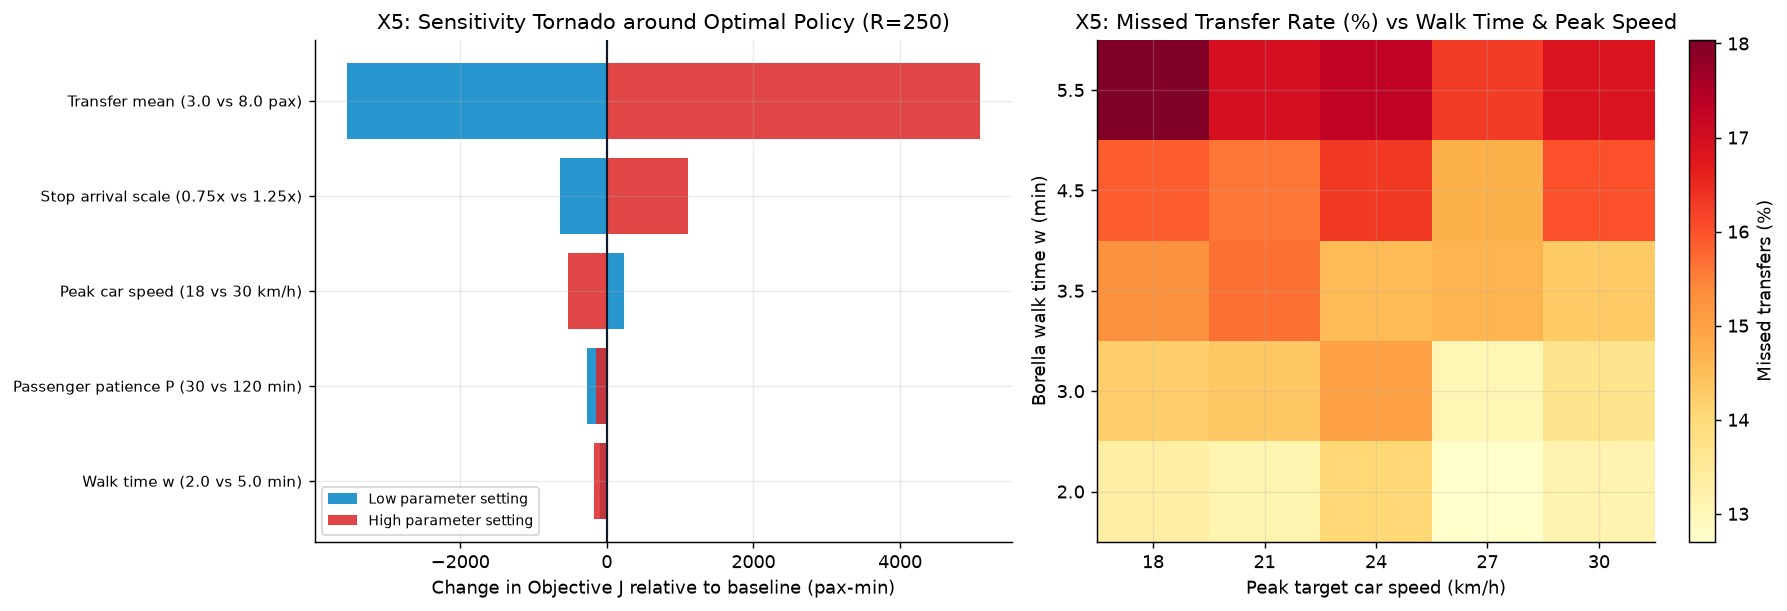


=== Extension X6: Vectorized Markov Chain Benchmark (2000 days x 240 slots) ===
Python loop time: 0.5505 s | Vectorized NumPy time: 0.0606 s | Measured speed-up: 9.1x


In [10]:
R_SENS = 250
sens_seeds = root_seed_sequence.spawn(R_SENS)
opt_shift_kw = {"shift_cm03_min": OPT_DELTA_MIN} if shift_target_route == "CM03" else {"shift_cm01_min": OPT_DELTA_MIN}
opt_pol = "none" if OPT_H_MIN == 0 else "realtime"

sens_base_days = [precompute_day_inputs(s, **opt_shift_kw) for s in sens_seeds]
sens_base = evaluate_policy_over_days(sens_base_days, opt_pol, OPT_H_MIN)
base_j_sens = sens_base["J_mean"]

v_reach_min = expected_speed_for_jam_param(JAM_PARAM_MAX)
v_reach_max = expected_speed_for_jam_param(JAM_PARAM_MIN)
v_pk_low = float(round(max(v_reach_min + 1.0, target_peak_kmph - 6.0), 1))
v_pk_high = float(round(min(v_reach_max - 1.0, target_peak_kmph + 6.0), 1))

sensitivity_specs = [
    ("Walk time w (2.0 vs 5.0 min)", {"walk_time_min": 2.0}, {"walk_time_min": 5.0}),
    ("Passenger patience P (30 vs 120 min)", {"patience_min": 30.0}, {"patience_min": 120.0}),
    ("Transfer mean (3.0 vs 8.0 pax)", {"transfer_mean_pax": 3.0}, {"transfer_mean_pax": 8.0}),
    ("Stop arrival scale (0.75x vs 1.25x)", {"arrival_rate_scale": 0.75}, {"arrival_rate_scale": 1.25}),
    (f"Peak car speed ({v_pk_low:.0f} vs {v_pk_high:.0f} km/h)", {"peak_speed_kmph": v_pk_low}, {"peak_speed_kmph": v_pk_high}),
]

def run_sens_case(case_kwargs):
    p_pk_mat = P_peak
    if "peak_speed_kmph" in case_kwargs:
        p_pk_val = calibrate_jam_param_bisection(case_kwargs["peak_speed_kmph"])
        p_pk_mat = build_parametric_transition_matrix(p_pk_val)
    days = [
        precompute_day_inputs(
            s,
            **opt_shift_kw,
            walk_time_min=case_kwargs.get("walk_time_min", WALK_TIME_PLACEHOLDER_MIN),
            transfer_mean_pax=case_kwargs.get("transfer_mean_pax", TRANSFER_MEAN_PAX),
            arrival_rate_scale=case_kwargs.get("arrival_rate_scale", 1.0),
            p_peak_mat=p_pk_mat,
            patience_min=case_kwargs.get("patience_min", PASSENGER_PATIENCE_MIN),
        )
        for s in sens_seeds
    ]
    return evaluate_policy_over_days(
        days,
        opt_pol,
        OPT_H_MIN,
        walk_time_min=case_kwargs.get("walk_time_min", WALK_TIME_PLACEHOLDER_MIN),
    )

tornado_rows = []
for label, low_kw, high_kw in sensitivity_specs:
    low_res = run_sens_case(low_kw)
    high_res = run_sens_case(high_kw)
    tornado_rows.append({
        "Parameter": label,
        "Low J": low_res["J_mean"],
        "High J": high_res["J_mean"],
        "Swing": abs(high_res["J_mean"] - low_res["J_mean"]),
        "Low Miss (%)": low_res["miss_all_pct"],
        "High Miss (%)": high_res["miss_all_pct"],
    })

tornado_df = pd.DataFrame(tornado_rows).sort_values("Swing", ascending=True)
print(f"=== Extension X5: Sensitivity Analysis around Joint Optimal Policy (Base J = {base_j_sens:.1f}, R = {R_SENS}) ===")
print(tornado_df.sort_values("Swing", ascending=False).round(2).to_string(index=False))

walk_sweep = np.array([2.0, 3.0, 3.5, 4.5, 5.5])
speed_sweep = np.round(np.linspace(v_pk_low, v_pk_high, 5), 1)
sens_2d = np.zeros((len(walk_sweep), len(speed_sweep)))
for r_i, w_val in enumerate(walk_sweep):
    for c_i, v_pk in enumerate(speed_sweep):
        out_2d = run_sens_case({"walk_time_min": float(w_val), "peak_speed_kmph": float(v_pk)})
        sens_2d[r_i, c_i] = out_2d["miss_all_pct"]

fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.8))
y_idx = np.arange(len(tornado_df))
axes[0].barh(y_idx, tornado_df["Low J"] - base_j_sens, color="#0284c7", alpha=0.85, label="Low parameter setting")
axes[0].barh(y_idx, tornado_df["High J"] - base_j_sens, color="#dc2626", alpha=0.85, label="High parameter setting")
axes[0].axvline(0.0, color="#0f172a", linewidth=1.2)
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(tornado_df["Parameter"], fontsize=8.5)
axes[0].set_xlabel("Change in Objective J relative to baseline (pax-min)")
axes[0].set_title(f"X5: Sensitivity Tornado around Optimal Policy (R={R_SENS})")
axes[0].legend(fontsize=8)

im_s = axes[1].imshow(sens_2d, aspect="auto", origin="lower", cmap="YlOrRd")
axes[1].set_xticks(range(len(speed_sweep)))
axes[1].set_xticklabels([f"{v:.0f}" for v in speed_sweep])
axes[1].set_yticks(range(len(walk_sweep)))
axes[1].set_yticklabels([f"{w:.1f}" for w in walk_sweep])
axes[1].set_xlabel("Peak target car speed (km/h)")
axes[1].set_ylabel("Borella walk time w (min)")
axes[1].set_title("X5: Missed Transfer Rate (%) vs Walk Time & Peak Speed")
plt.colorbar(im_s, ax=axes[1], label="Missed transfers (%)")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "sensitivity_tornado.png", bbox_inches="tight")
plt.show()

N_CHAINS_BENCH = 2000
N_SLOTS_BENCH = 240
bench_seeds = root_seed_sequence.spawn(2)
bench_rng_loop = np.random.default_rng(bench_seeds[0])
bench_rng_vec = np.random.default_rng(bench_seeds[1])

t0 = time.perf_counter()
loop_out = np.vstack([simulate_markov_chain_loop(P_peak, N_SLOTS_BENCH, bench_rng_loop) for _ in range(N_CHAINS_BENCH)])
t_loop_sec = time.perf_counter() - t0

t1 = time.perf_counter()
vec_out = simulate_markov_chain_vectorized(P_peak, N_SLOTS_BENCH, N_CHAINS_BENCH, bench_rng_vec)
t_vec_sec = time.perf_counter() - t1

assert loop_out.shape == vec_out.shape == (N_CHAINS_BENCH, N_SLOTS_BENCH)
speedup = t_loop_sec / max(1e-9, t_vec_sec)
print(f"\n=== Extension X6: Vectorized Markov Chain Benchmark ({N_CHAINS_BENCH} days x {N_SLOTS_BENCH} slots) ===")
print(f"Python loop time: {t_loop_sec:.4f} s | Vectorized NumPy time: {t_vec_sec:.4f} s | Measured speed-up: {speedup:.1f}x")

## 6. Discussion and limitations

*Provenance: AI-generated.*

### Key Insights

1. **Diagnosis of the current timetable (`E1`):** Missed connections are driven primarily by tight timing offsets at Borella (`-0.5 min` scheduled slack on four afternoon Kadawatha-to-Pettah trips `CM03-KAD-05..08` and on morning Pettah-to-Kadawatha `CM01-FOR-03`), compounded by stochastic traffic delays and occasional peak capacity saturation ($C = 80$).
2. **Holding alone vs coordinated timetable shift (`E2` & `E3`):** Holding at Borella rescues tight transfers when the connecting bus has spare capacity and the feeder is only slightly behind schedule, reducing missed transfers substantially for $h \in [2, 4]\text{ min}$. Combining a route-level shift $\Delta$ with moderate holding balances Group A and Group B simultaneously rather than over-penalizing one direction.
3. **Value of real-time ETA holding (`E4`):** When a feeder bus is delayed well past the connector's latest allowed departure $T_{c,\text{base}} + h$, schedule-based holding still holds the connecting bus (and its through-passengers) for the full $h$ minutes before giving up. Real-time ETA holding skips those uncatchable holds, retaining almost identical transfer protection while cutting wasted on-board passenger-minutes.
4. **Fleet capacity vs coordination (`E5`):** Comparing $C = 80$ against $C = \infty$ isolates peak-hour capacity refusals. With first-come-first-served boarding and passenger patience, removing the capacity limit changes the miss rate far less than timing coordination does, so most remaining misses are timing misses.
5. **Ticket validity (`E6`):** Almost every boarded through-ticket passenger leaves Borella within 120 minutes, so a 2-hour validity on the part-paid ticket is sufficient.

### Key Limitations and Future Work

- **Synthetic passenger and distance placeholders:** Stop-level passenger arrival rates $\lambda_{s,0}$, transfer demand $m_f$, Borella walking time $w = 3.5\text{ min}$, and stop-to-stop distances use flagged placeholders anchored to published Western Province loading profiles until direct field measurements and Google Maps segment distances are incorporated.
- **Independent corridor Markov chains:** In reality, Borella approach corridors share arterial congestion at common junctions; coupling adjacent road segments through a correlated traffic field would refine extreme delay tails.
- **Pooled traffic targets:** The Markov chain is calibrated to the mean speed of six `cmb_traffic` corridors, pooling Kandy Road segments (about 37 km/h off-peak) with inner-city Borella approaches (about 25 km/h). Per-leg speed factors $\alpha_\ell$ absorb the level difference but not differences in variability.
- **Passenger behaviour assumptions:** Patience $P = 60\text{ min}$, ticket validity $V = 120\text{ min}$ and the $60\text{ min}$ alternative-travel penalty are assumptions; $P$ is swept in the sensitivity analysis.
- **Borella boarding simplifications:** Boarding time at Borella on the connecting bus is not added to its dwell, and through-ticket passengers are not counted in the feeder bus load before Borella.
- **Borella timepoint interpolation:** Published timetables report bracketing timepoints only; GPS AVL logs from LMT-GO buses would replace the $\lambda = 0.5$ midpoint interpolation with observed Borella dwell and arrival distributions.

## 7. References

*Provenance: AI-generated.*

1. A. M. Law, *Simulation Modeling and Analysis*, 5th ed. New York, NY, USA: McGraw-Hill, 2015.
2. T. Amalan, "Analysis of Bus Passenger Demand and Supply: Case Study on Western Province, Sri Lanka," *International Journal of Scientific Research and Management (IJSRM)*, vol. 9, no. 11, pp. 2544-2554, Nov. 2021, doi: 10.18535/ijsrm/v9i11.em03.
3. N. I. Senaratna, "Colombo Traffic Index (`cmb_traffic`): Open Urban Road Travel-Time Dataset," GitHub repository (MIT License). [Online]. Available: https://github.com/nuuuwan/cmb_traffic
4. Lanka Metro Transit, "LMT-GO Official Route Schedules and Bus Specifications (Routes CM01 and CM03)," LMT-GO mobile application, accessed Nov. 10, 2026; cross-checked with https://metrobus.lk.
5. R. W. Hall, M. Dessouky, and Q. Lu, "Optimal holding times at transfer stations," *Computers & Industrial Engineering*, vol. 40, no. 4, pp. 379-397, 2001, doi: 10.1016/S0360-8352(01)00039-0.
6. S. M. Ross, *Simulation*, 6th ed. London, U.K.: Academic Press, 2023.